<a href="https://colab.research.google.com/github/douaaaaaaaaa18/ACM_DeepLearning_WCNS_Y4/blob/main/notebooks/data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> # project title : Automatic Modulation Classification (AMC) using Deep Learning
>
> ##### **Part 01 : data exploration and visualization**

## Purpose of This Notebook

- This notebook focuses on **dataset exploration and signal visualization** .  Before training any model, it is essential to understand what the data represents, how it is organized, whether it is balanced, and how the different modulation schemes behave as signals. The analysis will examine the dataset structure, investigate its quality and distributions, visualize I/Q signals in the time and frequency domains, compare modulation schemes, and study the effect of SNR on signal characteristics.

- The findings from this notebook will help guide preprocessing decisions, model development, and the interpretation of experimental results.

## outline :

1. data overview
2. data intergity and quality checks
3. dataset distribution analysis
4. modulation specific visualization
5. SNR and noise analysis
6. statistical signal analysis
7. frequency domain analysis
8. EDA and key findings

## 1. dataset overview

- This dataset : **the RadioML 2016.10a dataset** is a benchmark dataset designed for Automatic Modulation Classification (AMC). It contains digitally represented wireless signals belonging to different modulation schemes, observed under varying Signal to Noise Ratio (SNR) conditions.

- Each signal is represented using its In phase (I) and Quadrature (Q) components. These two components provide a complex valued representation of the received wireless signal, allowing the model to learn patterns related to the underlying modulation scheme.

- The dataset is organized according to two attributes: the modulation type and the SNR level. Each combination identifies a group of signal examples belonging to a particular modulation scheme and noise condition.

- In this section, we examine the dataset's structure, identify its modulation classes and SNR levels, and inspect the representation of an individual signal sample.

In [1]:
!git clone https://github.com/douaaaaaaaaa18/ACM_DeepLearning_WCNS_Y4.git

Cloning into 'ACM_DeepLearning_WCNS_Y4'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 47 (delta 23), reused 4 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 2.60 MiB | 11.39 MiB/s, done.
Resolving deltas: 100% (23/23), done.


In [2]:
!apt-get update -qq
!apt-get install git-lfs -y -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package git-lfs.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [3]:
!git lfs install

Git LFS initialized.


In [4]:
%cd /content/ACM_DeepLearning_WCNS_Y4
!git lfs pull

/content/ACM_DeepLearning_WCNS_Y4


In [5]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from pathlib import Path

In [8]:
from pathlib import Path

root = Path("/content")

print("ALL DATASET FILES FOUND:\n")

for file in root.rglob("*.pkl"):
    print(f"Path: {file}")
    print(f"Size: {file.stat().st_size / (1024**2):.2f} MB")
    print("-" * 50)

ALL DATASET FILES FOUND:

Path: /content/ACM_DeepLearning_WCNS_Y4/data/RML2016.10a_dict.pkl
Size: 611.23 MB
--------------------------------------------------


In [10]:
from pathlib import Path

DATA_PATH = Path(
    "/content/ACM_DeepLearning_WCNS_Y4/data/RML2016.10a_dict.pkl"
)

print("Dataset exists:", DATA_PATH.exists())
print(f"Dataset size: {DATA_PATH.stat().st_size / (1024**2):.2f} MB")

Dataset exists: True
Dataset size: 611.23 MB


In [11]:
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f, encoding="latin1")

print("Dataset successfully loaded!")
print("Data type:", type(data))
print("Number of entries:", len(data))

Dataset successfully loaded!
Data type: <class 'dict'>
Number of entries: 220


- The dataset is stored as a Python dictionary, each dictionary key is a tuple containing two elements:

  - **Modulation type** : identifies the modulation scheme used to generate the signal.
  - **SNR level** : indicates the Signal to Noise Ratio, expressed in decibels (dB).

- The value associated with each key is a NumPy array containing the signal examples corresponding to that particular modulation and SNR combination , for example, the key ('QPSK', 0) refers to the collection of QPSK signals generated at an SNR of 0 dB.
- This organization allows us to analyze a modulation scheme under different noise conditions, or compare different modulation schemes at the same SNR level.

- data shape : (modulation , SNR level) : array[...]

#### **modulation classes and SNR levels** :

- in this dataset , we have 11 modulation classes and 20 SNR levels, ranging from −20 dB to 18 dB in steps of 2 dB :

In [12]:
modulations = sorted(set(
    modulation for modulation, snr in data.keys()
))

snr_levels = sorted(set(
    snr for modulation, snr in data.keys()
))

print("Modulation classes:")
print(modulations)

print("\nNumber of classes:", len(modulations))

print("\nSNR levels:")
print(snr_levels)

print("\nNumber of SNR levels:", len(snr_levels))

Modulation classes:
['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']

Number of classes: 11

SNR levels:
[-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18]

Number of SNR levels: 20


- some examples :

In [13]:
first_5_keys = list(data.keys())[:5]

print(first_5_keys)

[('QPSK', 2), ('PAM4', 8), ('AM-DSB', -4), ('GFSK', 6), ('QAM64', 8)]


- The number of modulation classes tells us how many different categories the classification model must distinguish and the SNR levels represent different channel noise conditions under which those signals are observed.

- The number of (modulation, SNR) combinations is the number of dictionary entries ,we have 11 modulation classes × 20 SNR levels which gives 220 combinations.

- now each combination contains 1,000 examples, so , the dataset contains 220,000 signal examples in total.

- example : if we get ('QPSK', -10) , this means QPSK signals generated at −10 dB SNR , that is Noise is 100 times stronger

#### **signal representation : I and Q components** :

- the received wireless signals in this dataset are represented using two components: the In phase (I) component and the Quadrature (Q) component , together, these components represent a complex valued baseband signal:

  $$
  x[n] = I[n] + jQ[n]
  $$

  where ($I[n]$) represents the real component, ($Q[n]$) represents the imaginary component, and ($j$) is the imaginary unit.

- Each signal example contains two channels, corresponding to I and Q, with 128 samples per channel. Therefore, one signal has the shape:

  $$
  (2,128)
  $$

- The I/Q representation preserves information about both the amplitude and phase of the signal. These characteristics are important for distinguishing modulation schemes, and we can calculate the instantaneous magnitude and phase as:

  $$
  A[n] = \sqrt{I[n]^2 + Q[n]^2}
  $$

  $$
  \phi[n] = \operatorname{atan2}(Q[n],I[n])
  $$

  These representations will become useful later when analyzing signal characteristics and comparing modulation schemes.

- to inspect signals shape , we use one (modulation , SNR) combination as an example :

In [14]:
key = ('QPSK', 0)
signals = data[key]

print(type(signals))
print(signals.shape)

<class 'numpy.ndarray'>
(1000, 2, 128)


In [15]:
print(signals)

[[[-3.7118915e-04 -5.4411129e-03 -4.3649971e-03 ...  6.4952794e-04
   -5.0319540e-03  8.7778608e-04]
  [ 3.5347391e-03  4.0146210e-03  6.9022416e-03 ...  5.8002998e-03
   -8.4697193e-04  3.0146455e-03]]

 [[ 3.3324200e-03 -4.9043284e-03 -7.4990708e-03 ... -4.3057436e-03
   -4.4332333e-03 -4.2022262e-03]
  [ 1.3071371e-02  9.3062399e-03  1.9901933e-03 ... -5.8493162e-05
    8.7050525e-03  5.5839801e-03]]

 [[-7.3786308e-03 -9.0049691e-03 -7.1543083e-03 ... -2.3538829e-04
   -9.2258109e-03 -2.1626700e-03]
  [-4.3557212e-03 -1.1752046e-03 -4.2756740e-03 ...  8.9278342e-03
    5.7785679e-03  8.9772847e-03]]

 ...

 [[ 5.8132829e-03  1.7282370e-03  3.2984589e-03 ... -3.6808567e-03
   -7.3951301e-03 -8.9673465e-03]
  [ 4.6063741e-03 -5.3290691e-04 -4.2975698e-05 ... -4.1428162e-04
   -8.9056935e-04 -1.4182106e-03]]

 [[ 4.8551266e-03  3.5057787e-03  9.1454815e-03 ... -1.5035924e-03
   -3.3777710e-03 -4.6581822e-03]
  [ 5.2610142e-03 -1.9023910e-03 -2.3071593e-04 ...  1.0486016e-02
    1.0702

- The shape (1000, 2, 128) has three dimensions, the first dimension represents the number of signal examples in this modulation SNR group , the second dimension represents the two I/Q channels, and the third dimension represents the number of samples in each channel,so  the dataset gives us 1,000 independent signal examples for this particular modulation and SNR combination, with each example represented by 128 I samples and 128 Q samples.

In [16]:
signals[0]

array([[-3.7118915e-04, -5.4411129e-03, -4.3649971e-03, -1.2797160e-02,
        -6.7946240e-03, -3.2181013e-03, -9.4661629e-03, -2.2595669e-03,
        -9.4094770e-03, -1.8011840e-03, -4.5475587e-03, -2.9743742e-03,
        -6.0885963e-03, -6.2804935e-03, -1.1822740e-02, -2.0897049e-03,
        -6.6017904e-03, -4.3355911e-03, -4.6967394e-03, -4.9470910e-03,
        -9.0652844e-03,  4.5634582e-04,  7.9599405e-03,  1.5416724e-03,
         3.8131252e-03,  6.2258621e-03,  4.0639142e-04,  8.6961677e-03,
        -1.1764058e-03, -1.3059326e-03,  3.1404293e-03, -7.4116082e-04,
        -5.8296402e-03, -1.3849720e-03, -1.0848124e-02, -2.7156114e-03,
        -6.5761763e-03, -4.6055508e-03, -4.9553541e-03, -7.1325456e-03,
        -3.2211794e-03, -2.0385613e-03, -5.5004698e-03, -4.4152597e-03,
         5.4797330e-03,  4.4926917e-03,  6.4913630e-03, -1.5545944e-03,
         1.1259979e-02,  3.3214579e-03,  4.1291304e-03,  5.8168191e-03,
         4.1158265e-03,  1.9734609e-03, -9.4656175e-04, -8.19030

- i compoent

In [17]:
signals[0,0]


array([-3.7118915e-04, -5.4411129e-03, -4.3649971e-03, -1.2797160e-02,
       -6.7946240e-03, -3.2181013e-03, -9.4661629e-03, -2.2595669e-03,
       -9.4094770e-03, -1.8011840e-03, -4.5475587e-03, -2.9743742e-03,
       -6.0885963e-03, -6.2804935e-03, -1.1822740e-02, -2.0897049e-03,
       -6.6017904e-03, -4.3355911e-03, -4.6967394e-03, -4.9470910e-03,
       -9.0652844e-03,  4.5634582e-04,  7.9599405e-03,  1.5416724e-03,
        3.8131252e-03,  6.2258621e-03,  4.0639142e-04,  8.6961677e-03,
       -1.1764058e-03, -1.3059326e-03,  3.1404293e-03, -7.4116082e-04,
       -5.8296402e-03, -1.3849720e-03, -1.0848124e-02, -2.7156114e-03,
       -6.5761763e-03, -4.6055508e-03, -4.9553541e-03, -7.1325456e-03,
       -3.2211794e-03, -2.0385613e-03, -5.5004698e-03, -4.4152597e-03,
        5.4797330e-03,  4.4926917e-03,  6.4913630e-03, -1.5545944e-03,
        1.1259979e-02,  3.3214579e-03,  4.1291304e-03,  5.8168191e-03,
        4.1158265e-03,  1.9734609e-03, -9.4656175e-04, -8.1903050e-03,
      

- q component

In [18]:
signals[0,1]

array([ 3.5347391e-03,  4.0146210e-03,  6.9022416e-03,  4.2038853e-03,
       -2.0028404e-03,  6.9366409e-03, -1.2154188e-03,  8.9079197e-03,
        1.3625186e-03,  8.5556842e-03,  2.0015175e-03,  8.3061801e-03,
        9.0954388e-03,  1.1475704e-03,  4.3587966e-04,  1.0560833e-02,
        4.9663009e-03, -1.8130959e-03,  7.3898146e-03,  3.5695088e-04,
        1.0996503e-03, -5.6937570e-03, -4.3157213e-03, -1.0866881e-02,
       -6.4028287e-03, -7.0743379e-03, -4.9486957e-03, -6.9452203e-03,
        2.8862106e-03, -3.3059716e-03, -2.4683811e-04,  2.1657951e-03,
        4.5042578e-03,  3.4919879e-03,  1.0276623e-02,  3.6595280e-03,
        5.9008645e-03,  5.3149629e-03,  1.5908980e-03, -7.9512369e-04,
       -7.4940221e-03, -1.0948248e-02, -6.9929734e-03, -5.4971278e-03,
       -5.3350478e-03,  1.5191643e-03, -5.9517781e-04, -3.0300154e-03,
        5.3274855e-03,  2.8395641e-03,  5.5257832e-03,  6.2930314e-03,
        9.4647234e-04,  1.5238843e-02,  8.7277507e-03,  4.0102089e-03,
      

- results summary :

| Property | Expected value |
| :--- | :--- |
| **Selected key** | `('QPSK', 0)` |
| **Array shape** | `(1000, 2, 128)` |
| **Individual signal shape** | `(2, 128)` |
| **I component shape** | `(128,)` |
| **Q component shape** | `(128,)` |

In [19]:
key = ('QPSK', 0)

signals = data[key]

example = signals[0]

I = example[0, :]
Q = example[1, :]

n = np.arange(128)

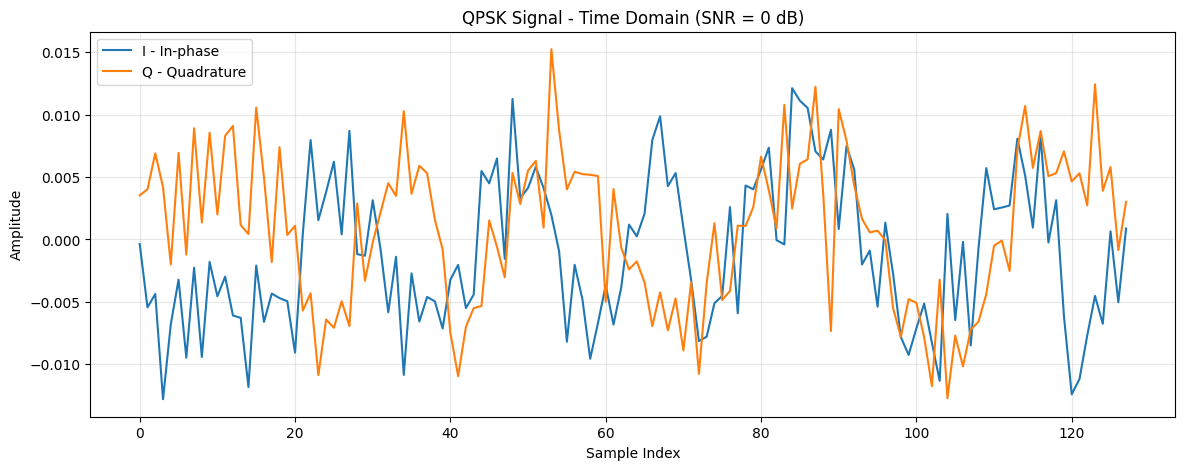

In [20]:
plt.figure(figsize=(14, 5))

plt.plot(n, I, label='I - In-phase')
plt.plot(n, Q, label='Q - Quadrature')

plt.title('QPSK Signal - Time Domain (SNR = 0 dB)')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

- The **time domain** plot shows the evolution of the In phase (I) and Quadrature (Q) components of a QPSK signal at 0 dB SNR over 128 samples , both components fluctuate around zero, with noticeable variations in their amplitudes throughout the observation window, these fluctuations reflect the signal's modulation characteristics as well as the effects of noise and waveform variations ,since I and Q represent two orthogonal components of the same complex signal, analyzing them together provides a more complete representation of the received signal.
- At 0 dB SNR, the signal is observed under a condition where signal power and noise power are equal, making the received waveform relatively noisy.

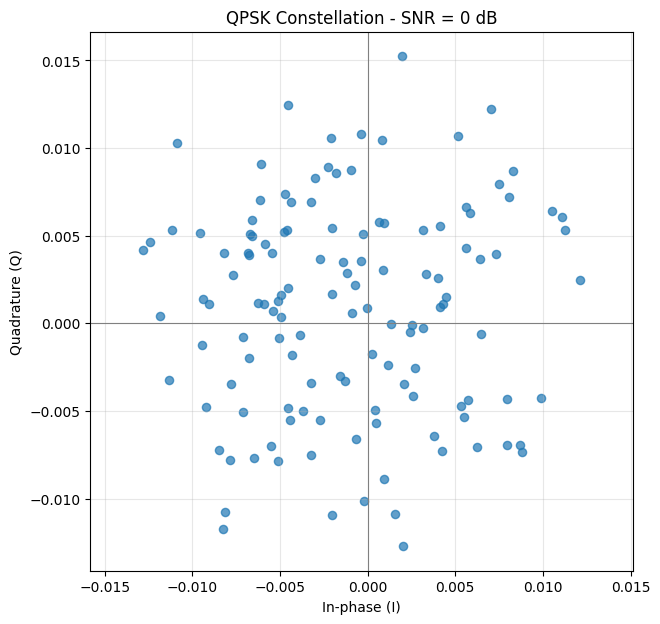

In [21]:
plt.figure(figsize=(7, 7))

plt.scatter(I, Q, s=35, alpha=0.7)

plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)

plt.title('QPSK Constellation - SNR = 0 dB')
plt.xlabel('In-phase (I)')
plt.ylabel('Quadrature (Q)')

plt.axis('equal')
plt.grid(alpha=0.3)
plt.show()

- here we observe the componets together , its a constellation diagram mapping the In phase ($I$) values against the Quadrature ($Q$) values. We plot $I$ and $Q$ against each other to visualize the signal's phase and amplitude states on a 2D complex plane.
- Looking at the results for an $\text{SNR}$ of $0\text{ dB}$, the high noise level causes the sample points to form a scattered, overlapping cloud instead of four distinct clusters, clearly showing how severe noise distorts the signal and blurs its constellation states.

- note :
  $$
  A[n]=\sqrt{I[n]^2+Q[n]^2}
  $$

  $$
  \phi[n]=\operatorname{atan2}(Q[n],I[n])
  $$

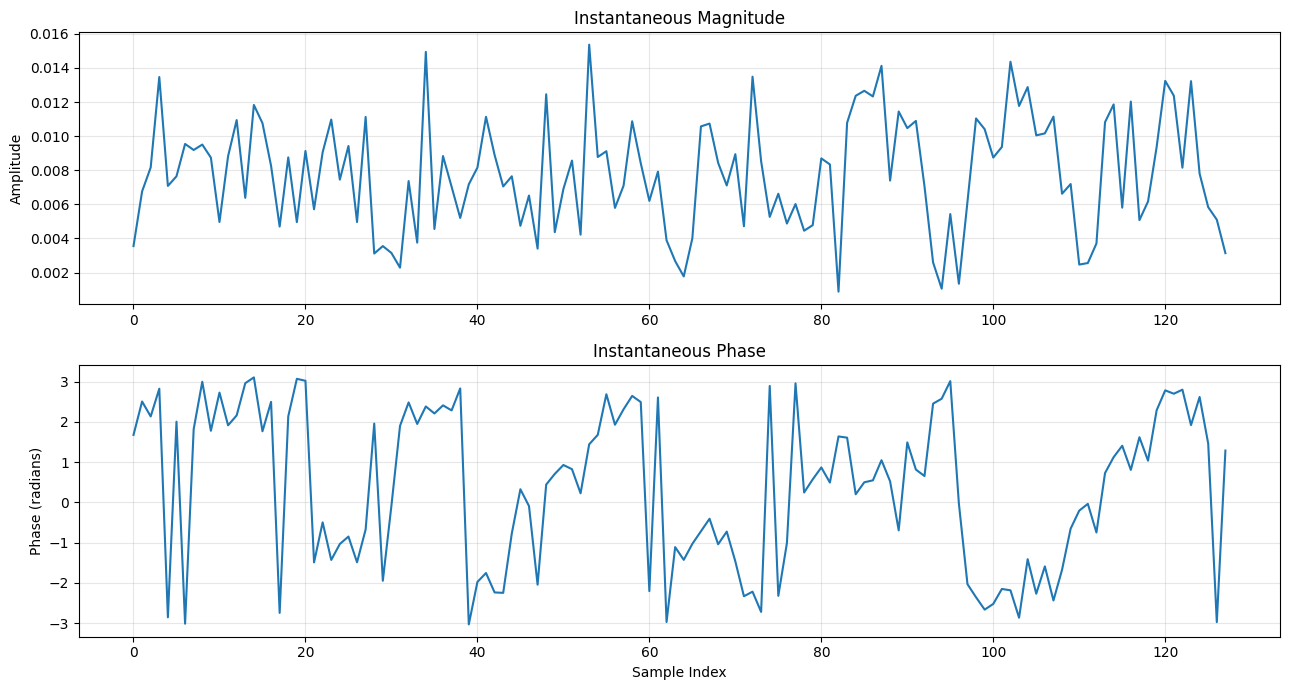

In [22]:
amplitude = np.sqrt(I**2 + Q**2)
phase = np.arctan2(Q, I)

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

axes[0].plot(n, amplitude)
axes[0].set_title('Instantaneous Magnitude')
axes[0].set_ylabel('Amplitude')
axes[0].grid(alpha=0.3)

axes[1].plot(n, phase)
axes[1].set_title('Instantaneous Phase')
axes[1].set_xlabel('Sample Index')
axes[1].set_ylabel('Phase (radians)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- here we plot the instantaneous magnitude (amplitude) and instantaneous phase across the 128 time series samples ($n$). We track magnitude to see how the signal energy fluctuates over time, and phase to observe how the angle shifts.
- Looking at the results at $0\text{ dB}$ SNR, the magnitude fluctuates erratically due to heavy noise, and the phase jumps jaggedly across the full $[-\pi, \pi]$ range without stable plateaus, showing how noise completely disrupts the expected QPSK symbol transitions

## 2. data intergity and quality checks

- in this section , we verify the integrity and quality of the dataset , since incorrect dimensions, inconsistent sample counts, missing values, or invalid numerical values can lead to unreliable analysis and negatively affect model training.

- we perform a series of validation checks on the dataset , and examine its dictionary structure, verify the consistency of signal dimensions, inspect data types, identify invalid numerical values, and check the completeness and consistency of the (modulation , SNR) combinations.


first we start by checking that each dictionary key is be a tuple containing exactly two elements : a modulation label and an SNR value :

In [23]:
print("DATASET STRUCTURE VALIDATION")

print("Is dictionary:", isinstance(data, dict))
print("Number of entries:", len(data))

DATASET STRUCTURE VALIDATION
Is dictionary: True
Number of entries: 220


In [24]:
valid_keys = all(
    isinstance(key, tuple) and len(key) == 2
    for key in data.keys()
)

print("All keys are valid tuples:", valid_keys)

All keys are valid tuples: True


In [25]:
sample_key = next(iter(data.keys()))

print("\nExample key:", sample_key)
print("Modulation type:", type(sample_key[0]))
print("SNR type:", type(sample_key[1]))


Example key: ('QPSK', 2)
Modulation type: <class 'str'>
SNR type: <class 'int'>


we verify expected modulation and SNR combinations :

In [26]:
expected_modulations = {
    "BPSK", "QPSK", "8PSK", "QAM16", "QAM64",
    "PAM4", "CPFSK", "GFSK", "AM-DSB", "AM-SSB", "WBFM"
}

expected_snr = set(range(-20, 20, 2))

expected_keys = {
    (mod, snr)
    for mod in expected_modulations
    for snr in expected_snr
}

actual_keys = set(data.keys())

missing_keys = expected_keys - actual_keys
unexpected_keys = actual_keys - expected_keys

print("Expected combinations:", len(expected_keys))
print("Actual combinations:", len(actual_keys))
print("Missing combinations:", len(missing_keys))
print("Unexpected combinations:", len(unexpected_keys))

print("\nMissing keys:", missing_keys)
print("Unexpected keys:", unexpected_keys)

Expected combinations: 220
Actual combinations: 220
Missing combinations: 0
Unexpected combinations: 0

Missing keys: set()
Unexpected keys: set()


we check signal dimensions and shapes

In [27]:
shape_report = []

for key, signals in data.items():
    shape_report.append({
        "Modulation": key[0],
        "SNR (dB)": key[1],
        "Shape": signals.shape,
        "Valid Shape": (
            isinstance(signals, np.ndarray)
            and signals.ndim == 3
            and signals.shape[1:] == (2, 128)
        )
    })

shape_df = pd.DataFrame(shape_report)

display(shape_df.head(10))

print("Unique shapes:", shape_df["Shape"].nunique())
print("All shapes valid:", shape_df["Valid Shape"].all())
print("Invalid entries:", (~shape_df["Valid Shape"]).sum())

,Modulation,SNR (dB),Shape,Valid Shape
0,QPSK,2,"(1000, 2, 128)",True
1,PAM4,8,"(1000, 2, 128)",True
2,AM-DSB,-4,"(1000, 2, 128)",True
3,GFSK,6,"(1000, 2, 128)",True
4,QAM64,8,"(1000, 2, 128)",True
5,AM-SSB,12,"(1000, 2, 128)",True
6,8PSK,8,"(1000, 2, 128)",True
7,8PSK,12,"(1000, 2, 128)",True
8,QAM64,-6,"(1000, 2, 128)",True
9,QAM16,2,"(1000, 2, 128)",True


Unique shapes: 1
All shapes valid: True
Invalid entries: 0


we check data types :

In [28]:
dtype_report = []

for key, signals in data.items():
    dtype_report.append({
        "Modulation": key[0],
        "SNR (dB)": key[1],
        "Data Type": str(signals.dtype),
        "Is Numeric": np.issubdtype(signals.dtype, np.number)
    })

dtype_df = pd.DataFrame(dtype_report)

display(dtype_df["Data Type"].value_counts().rename_axis(
    "Data Type"
).reset_index(name="Number of Entries"))

print("\nAll arrays have numerical data types:",
      dtype_df["Is Numeric"].all())

,Data Type,Number of Entries
0,float32,220



All arrays have numerical data types: True


checking missing values and invalid numerical values :

In [29]:
total_values = 0
total_nan = 0
total_pos_inf = 0
total_neg_inf = 0

invalid_entries = []

for key, signals in data.items():

    nan_count = np.isnan(signals).sum()
    pos_inf_count = np.isposinf(signals).sum()
    neg_inf_count = np.isneginf(signals).sum()

    total_values += signals.size
    total_nan += nan_count
    total_pos_inf += pos_inf_count
    total_neg_inf += neg_inf_count

    if nan_count > 0 or pos_inf_count > 0 or neg_inf_count > 0:
        invalid_entries.append({
            "Key": key,
            "NaN": nan_count,
            "+Inf": pos_inf_count,
            "-Inf": neg_inf_count
        })

print("Total numerical values:", f"{total_values:,}")
print("NaN values:", f"{total_nan:,}")
print("Positive infinity:", f"{total_pos_inf:,}")
print("Negative infinity:", f"{total_neg_inf:,}")

print("\nEntries containing invalid values:", len(invalid_entries))

if invalid_entries:
    display(pd.DataFrame(invalid_entries))
else:
    print("No NaN or infinite values found.")

Total numerical values: 56,320,000
NaN values: 0
Positive infinity: 0
Negative infinity: 0

Entries containing invalid values: 0
No NaN or infinite values found.


verifying sample counts per combination :

In [30]:
sample_counts = pd.DataFrame([
    {
        "Modulation": modulation,
        "SNR (dB)": snr,
        "Number of Samples": len(signals)
    }
    for (modulation, snr), signals in data.items()
])

print("Minimum samples per combination:",
      sample_counts["Number of Samples"].min())

print("Maximum samples per combination:",
      sample_counts["Number of Samples"].max())

print("Total number of samples:",
      f"{sample_counts['Number of Samples'].sum():,}")

print("Combinations with unexpected sample counts:",
      (sample_counts["Number of Samples"] != 1000).sum())

Minimum samples per combination: 1000
Maximum samples per combination: 1000
Total number of samples: 220,000
Combinations with unexpected sample counts: 0


- overall intergity summary :

In [31]:
integrity_checks = {
    "Valid dictionary structure": isinstance(data, dict),
    "Expected combinations complete": len(missing_keys) == 0
        and len(unexpected_keys) == 0,
    "Consistent signal shapes": shape_df["Valid Shape"].all(),
    "Numerical data types": dtype_df["Is Numeric"].all(),
    "No NaN values": total_nan == 0,
    "No positive infinity": total_pos_inf == 0,
    "No negative infinity": total_neg_inf == 0,
    "Consistent sample counts": (
        sample_counts["Number of Samples"] == 1000
    ).all()
}

integrity_summary = pd.DataFrame(
    [
        {
            "Check": check,
            "Result": "PASS" if passed else "FAIL"
        }
        for check, passed in integrity_checks.items()
    ]
)

display(integrity_summary)

print("\nOverall integrity:",
      "PASSED" if all(integrity_checks.values()) else "REQUIRES ATTENTION")

,Check,Result
0,Valid dictionary structure,PASS
1,Expected combinations complete,PASS
2,Consistent signal shapes,PASS
3,Numerical data types,PASS
4,No NaN values,PASS
5,No positive infinity,PASS
6,No negative infinity,PASS
7,Consistent sample counts,PASS



Overall integrity: PASSED


#### **interpretation** :

- The integrity assessment confirms that the dataset satisfies all the structural and numerical validation criteria established for this analysis ,the dataset contains all 220 expected (modulation,SNR) combinations, with no missing or unexpected entries. Furthermore, all signal arrays follow the expected dimensions, ensuring a consistent representation of the In phase and Quadrature components across the dataset, also , the numerical data types are suitable for mathematical operations, and no NaN or infinite values were detected.

- The validation also confirms that every (modulation,SNR) combination contains the expected number of signal examples, resulting in a consistent dataset structure.
- Overall, these results indicate that the dataset is structurally consistent and numerically valid, making it suitable for the subsequent exploratory analysis and deep learning experiments.

## 3. dataset distribution analysis

- After verifying the structural and numerical integrity of the dataset, we now investigate how the signal examples are distributed across modulation classes and Signal to Noise Ratio (SNR) levels.

- Understanding the dataset distribution is important for identifying potential class imbalance or uneven representation across different channel conditions, since such imbalances may influence the learning process and affect the performance of an Automatic Modulation Classification model.

- In this section, we analyze the number of samples belonging to each modulation class, examine the distribution across SNR levels, and investigate the joint distribution of modulation classes and SNR conditions.

#### **distribution across modulation classes** :

In [32]:
overview = pd.DataFrame([
    {
        "Modulation": modulation,
        "SNR (dB)": snr,
        "Number of Examples": len(signals)
    }
    for (modulation, snr), signals in data.items()
])

,Number of Samples
QPSK,20000
PAM4,20000
AM-DSB,20000
GFSK,20000
QAM64,20000
AM-SSB,20000
8PSK,20000
QAM16,20000
WBFM,20000
CPFSK,20000


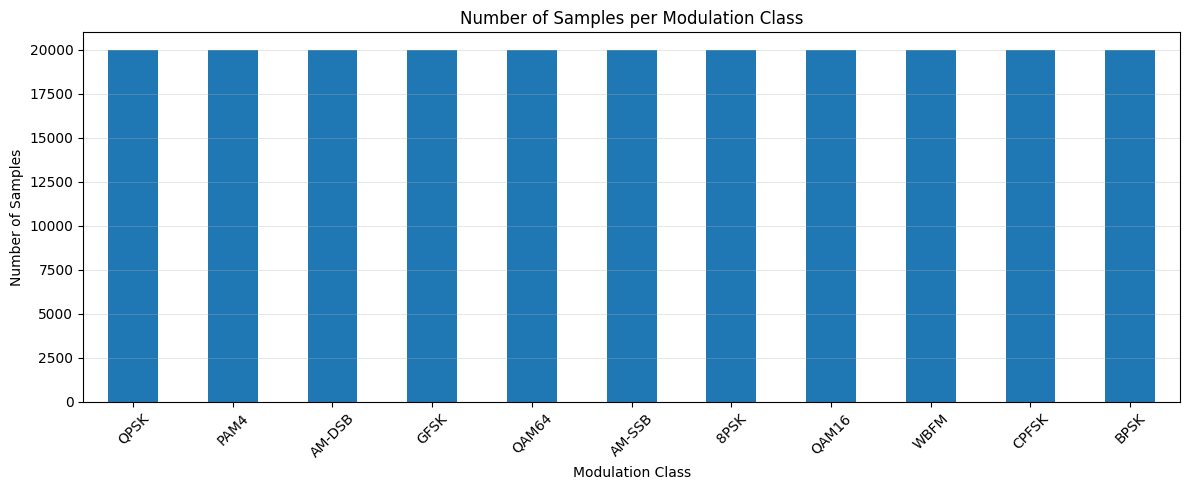

In [33]:
class_distribution = {}

for (modulation, snr), signals in data.items():
    class_distribution[modulation] = (
        class_distribution.get(modulation, 0) + len(signals)
    )

class_distribution = pd.Series(class_distribution).sort_values(
    ascending=False
)

display(class_distribution.to_frame("Number of Samples"))

plt.figure(figsize=(12, 5))
class_distribution.plot(kind="bar")

plt.title("Number of Samples per Modulation Class")
plt.xlabel("Modulation Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

- The class distribution analysis shows that all 11 modulation classes contain exactly 20,000 signal examples each , this uniform distribution indicates that the dataset is balanced with respect to modulation classes, meaning that no modulation class is overrepresented or underrepresented. Consequently, a classification model trained on this dataset is less likely to favor a particular modulation simply because it appears more frequently in the training data.
- This provides a fairer basis for comparing classification performance across modulation types.

#### **number of samples per SNR level** :

,Number of Samples
-20,11000
-18,11000
-16,11000
-14,11000
-12,11000
-10,11000
-8,11000
-6,11000
-4,11000
-2,11000


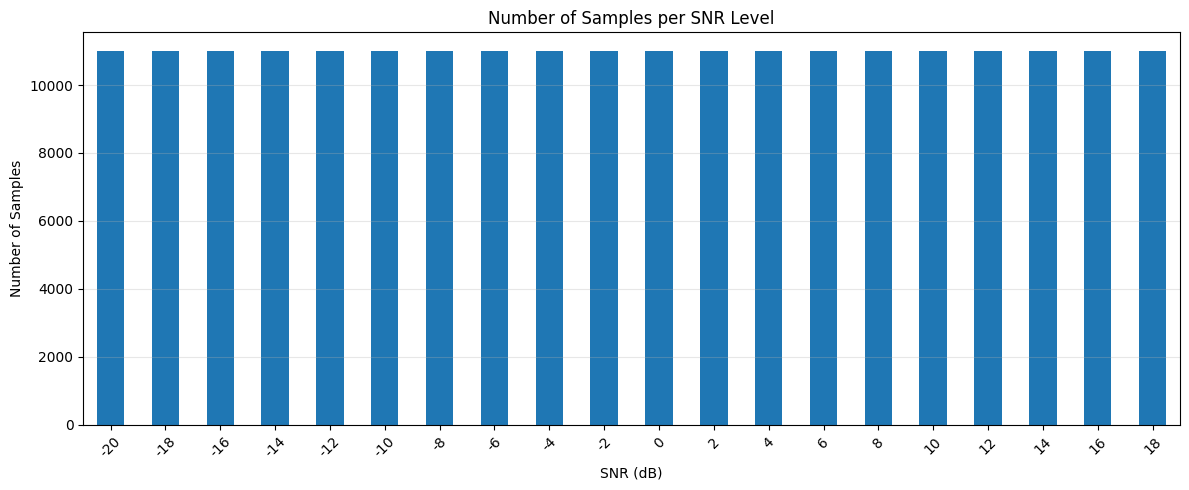

In [34]:
snr_distribution = {}

for (modulation, snr), signals in data.items():
    snr_distribution[snr] = (
        snr_distribution.get(snr, 0) + len(signals)
    )

snr_distribution = pd.Series(snr_distribution).sort_index()

display(snr_distribution.to_frame("Number of Samples"))

plt.figure(figsize=(12, 5))
snr_distribution.plot(kind="bar")

plt.title("Number of Samples per SNR Level")
plt.xlabel("SNR (dB)")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

- The SNR distribution analysis shows that each of the 20 SNR levels contains exactly 11,000 signal examples, this uniform distribution results from the contribution of 1,000 examples from each of the 11 modulation classes at every SNR level. Therefore, the dataset is balanced not only across modulation classes but also across noise conditions.
- This ensures that no SNR level dominates the dataset and allows the model's classification performance to be evaluated across the full range of signal to noise conditions, from highly noisy signals to relatively clean signals.

#### **joint distribution of modulatio classes and SNR levels** :

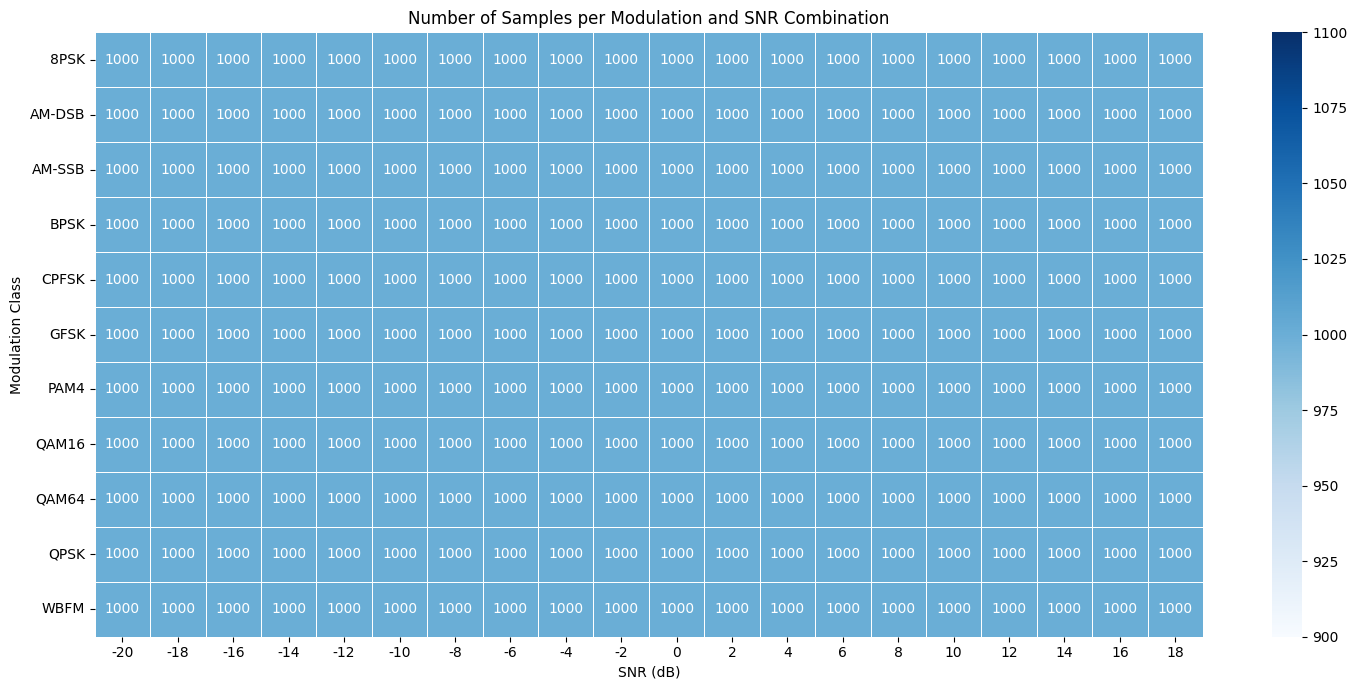

In [35]:
distribution_matrix = pd.DataFrame(
    {
        snr: {
            modulation: len(data[(modulation, snr)])
            for modulation in modulations
        }
        for snr in snr_levels
    }
)

plt.figure(figsize=(15, 7))

sns.heatmap(
    distribution_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Number of Samples per Modulation and SNR Combination")
plt.xlabel("SNR (dB)")
plt.ylabel("Modulation Class")
plt.tight_layout()
plt.show()

- The joint distribution heatmap confirms that every (modulation,SNR) combination contains exactly 1,000 signal examples. The uniform values across all cells demonstrate that the dataset is perfectly balanced across both modulation classes and SNR levels, with no missing or underrepresented combinations, and this means that every modulation scheme is represented equally under every noise condition, so, the dataset provides a consistent foundation for studying how signal quality affects modulation classification without introducing sample count imbalance between different combinations.

#### **section summary** :

- Overall , the distribution analysis demonstrates that our dataset is structurally balanced across its two main dimensions: modulation class and SNR level.
- Each of the 11 modulation classes contains 20,000 examples, each of the 20 SNR levels contains 11,000 examples, and every individual (modulation,SNR) combination contains 1,000 examples.
- This uniform distribution eliminates sample count imbalance as a major source of bias during classification experiments.


## 4. modulation specific visualization

#### **I/Q time-domain signals**

- A modulated signal is represented by its in phase (I) and quadrature (Q) components, which together describe its complex baseband representation, plotting these components over time allows us to observe how the signal waveform evolves and how its characteristics differ between modulation schemes.
- By examining all modulation classes under the same SNR condition, we can compare their temporal behavior while minimizing the influence of different noise levels.
- These visualizations provide an initial understanding of the diversity of signal patterns present in the dataset.

In [36]:
selected_snr = 18

modulations = sorted({modulation for modulation, snr in data.keys()})

print(f"Modulation classes: {len(modulations)}")
print(f"Classes: {modulations}")
print(f"Selected SNR: {selected_snr} dB")

Modulation classes: 11
Classes: ['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']
Selected SNR: 18 dB


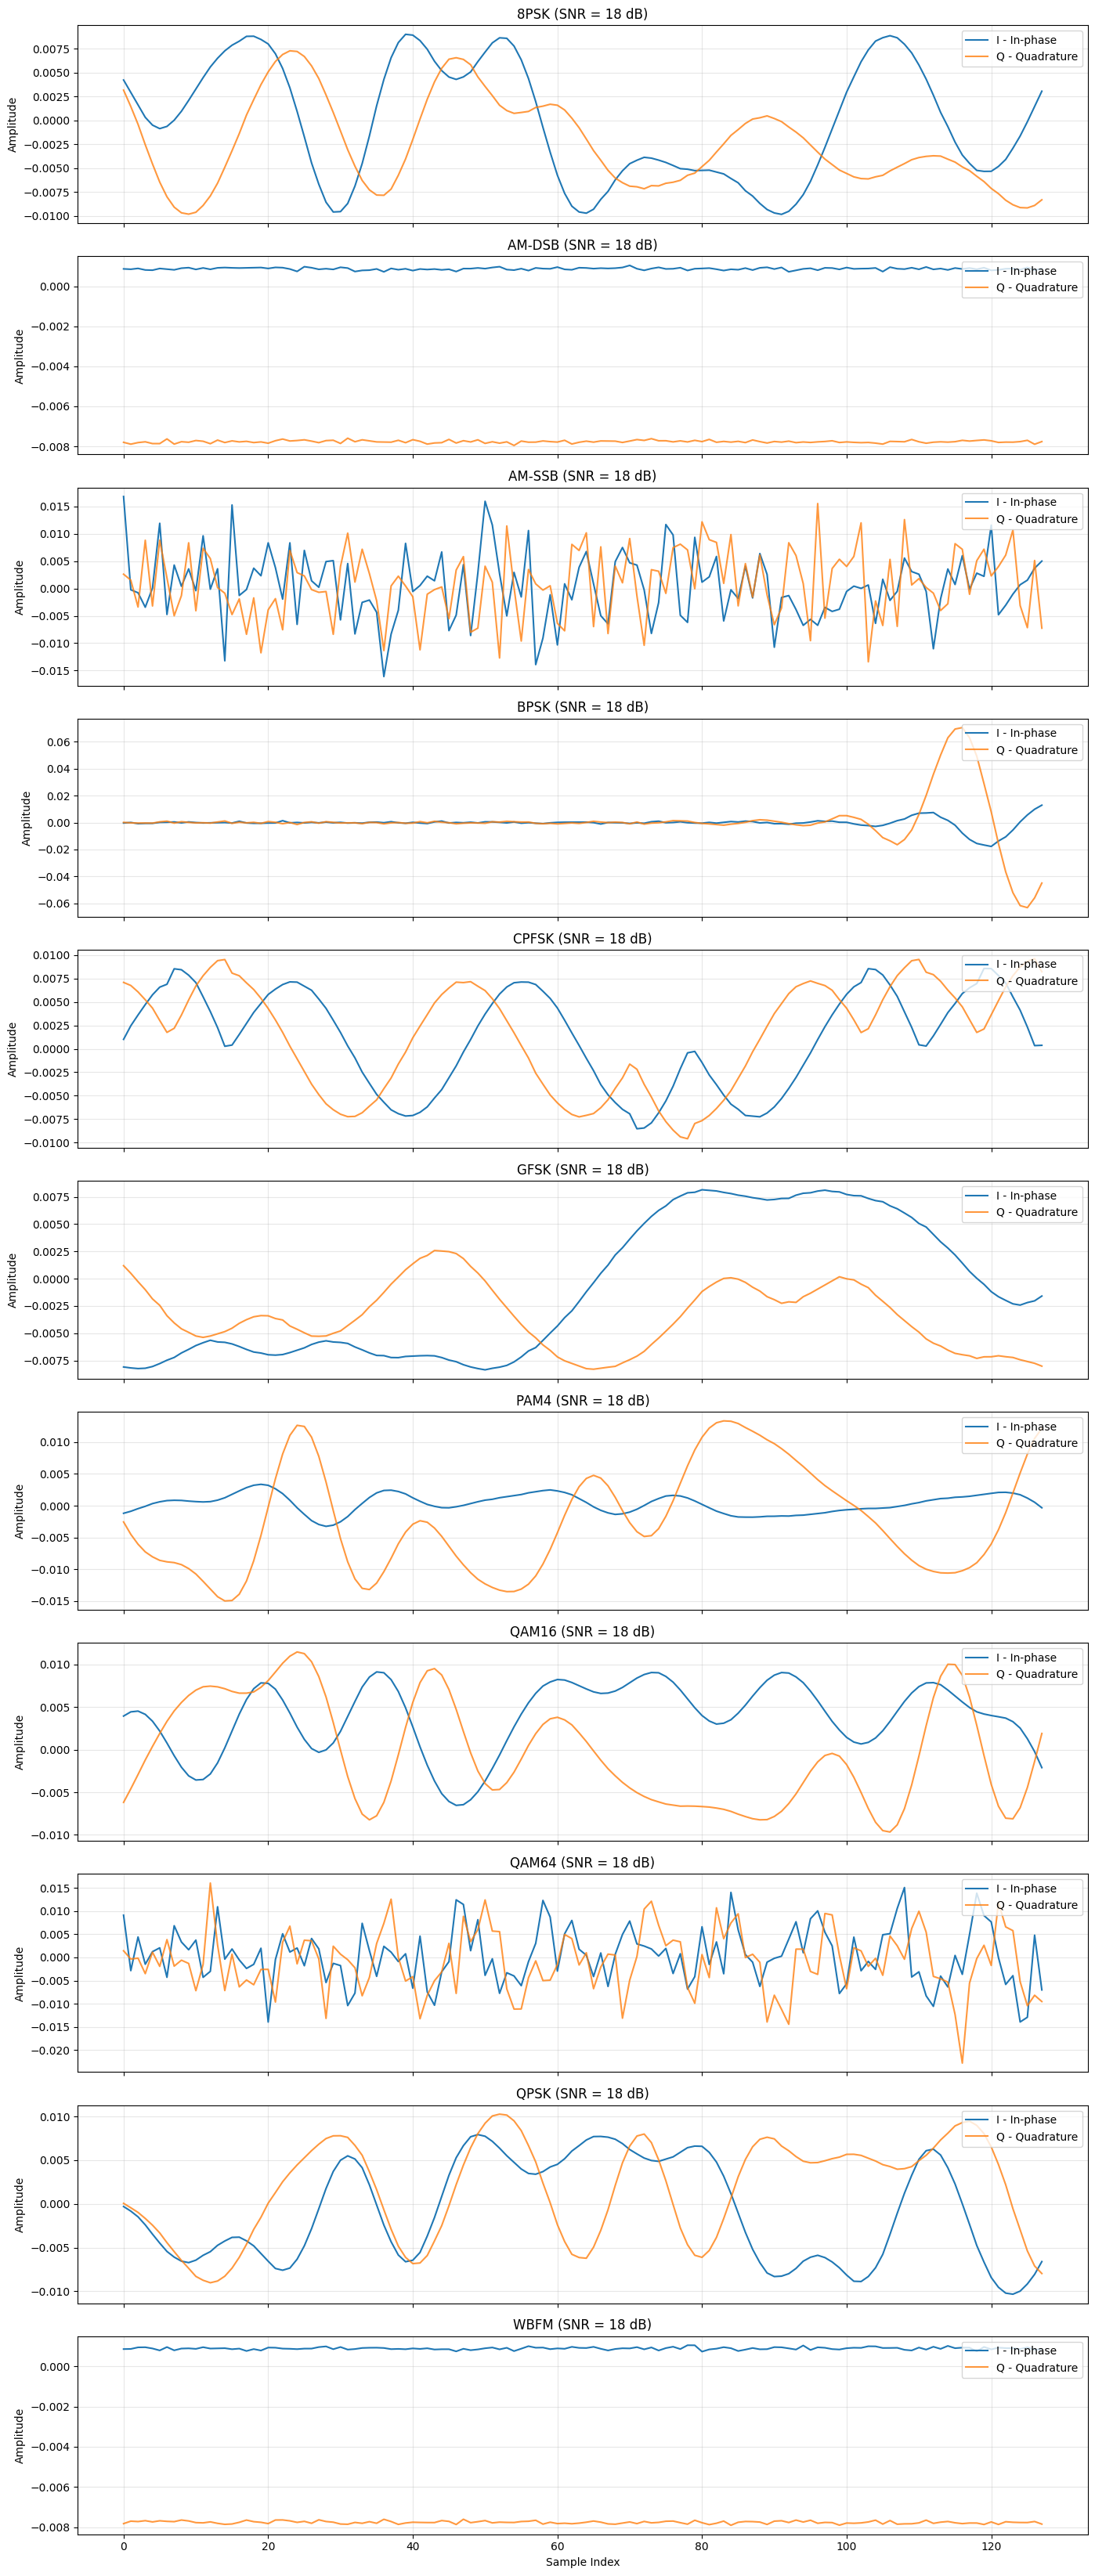

In [37]:
fig, axes = plt.subplots(
    len(modulations), 1,
    figsize=(14, 3 * len(modulations)),
    sharex=True
)

for ax, modulation in zip(axes, modulations):

    example = data[(modulation, selected_snr)][0]

    I = example[0]
    Q = example[1]
    samples = np.arange(len(I))

    ax.plot(samples, I, label="I - In-phase")
    ax.plot(samples, Q, label="Q - Quadrature", alpha=0.8)

    ax.set_title(f"{modulation} (SNR = {selected_snr} dB)")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Sample Index")

plt.tight_layout()
plt.show()

- The time domain visualization illustrates the variations of the in phase (I) and quadrature (Q) components across all 11 modulation classes at an SNR of 18 dB. Although the signals share the same I/Q representation, their temporal patterns differ according to their underlying modulation characteristics.
- Phase based schemes, including BPSK, QPSK, and 8PSK, encode information through phase variations, while amplitude related schemes such as PAM4, QAM16, and QAM64 involve variations in signal amplitude and/or phase , Frequency based schemes, including CPFSK, GFSK, and WBFM, exhibit temporal patterns associated with changes in instantaneous frequency , and the AM-DSB and AM-SSB signals also display their own amplitude modulation characteristics.
- Since the selected SNR is relatively high, the signals are observed under comparatively low noise conditions, making their underlying waveform patterns easier to examine.
- Overall, this visualization demonstrates the diversity of temporal signal characteristics across modulation schemes and motivates further investigation using constellation, amplitude, and phase representations.

#### **I/Q constellation diagrams**

- A constellation diagram represents complex signal samples in the I/Q plane, where the horizontal axis corresponds to the in phase component and the vertical axis corresponds to the quadrature component.
- It provides a visual way to examine the amplitude and phase characteristics of modulated signals, different modulation schemes can produce distinct spatial patterns, making constellation diagrams particularly useful for comparing modulation families.
- In this analysis, the I/Q samples of one signal example from each modulation class are plotted using the same SNR level, since the dataset contains sampled waveforms, these plots represent all available time samples rather than necessarily showing only ideal symbol decision points.
- Therefore, the resulting point clouds should be interpreted as sampled signal distributions, not assumed to be perfect theoretical constellations.

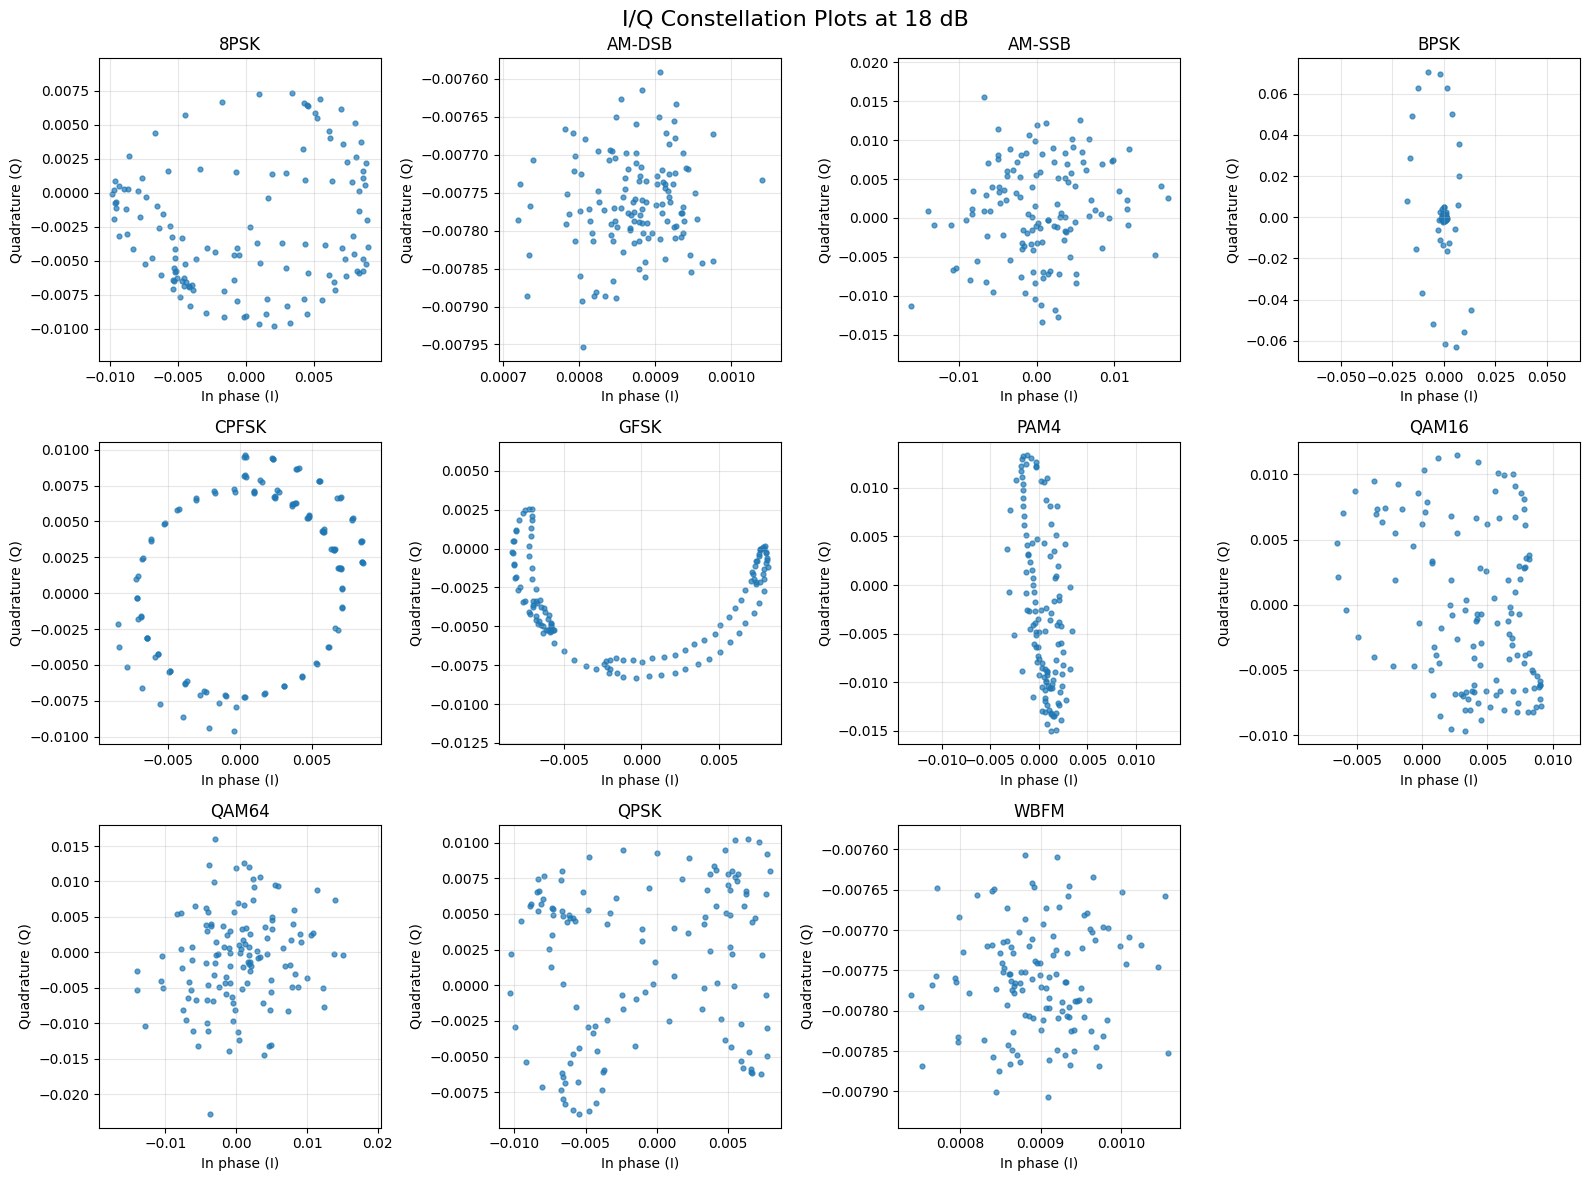

In [38]:
ncols = 4
nrows = int(np.ceil(len(modulations) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 4 * nrows)
)

axes = axes.flatten()

for i, modulation in enumerate(modulations):

    example = data[(modulation, selected_snr)][0]

    I = example[0]
    Q = example[1]

    axes[i].scatter(I, Q, s=12, alpha=0.7)

    axes[i].set_title(modulation)
    axes[i].set_xlabel("In phase (I)")
    axes[i].set_ylabel("Quadrature (Q)")
    axes[i].grid(alpha=0.3)
    axes[i].set_aspect("equal", adjustable="datalim")

for i in range(len(modulations), len(axes)):
    axes[i].axis("off")

fig.suptitle(
    f"I/Q Constellation Plots at {selected_snr} dB",
    fontsize=16
)

plt.tight_layout()
plt.show()

- The I/Q scatter plots reveal distinct spatial patterns across the modulation classes at 18 dB SNR. While 8PSK and CPFSK exhibit approximately circular distributions and GFSK forms a curved pattern, BPSK and PAM4 show predominantly vertical distributions. QPSK, QAM16, and QAM64 display more dispersed two dimensional patterns, whereas AM-DSB and WBFM form tightly concentrated clusters. - These differences reflect variations in the amplitude and phase characteristics of the signals.

#### **Instantaneous amplitude**

- The instantaneous amplitude, also called the signal envelope magnitude, describes the magnitude of the complex baseband signal at each sample, it is calculated from the in phase and quadrature components using $(A[n]=\sqrt{I[n]^2+Q[n]^2})$.
- Examining amplitude variations over time helps identify differences in how modulation schemes encode information through signal magnitude, some modulation schemes maintain approximately constant envelope characteristics, while others allow amplitude variations as part of their modulation process.
- Comparing the amplitude profiles of all modulation classes therefore provides another perspective on their signal characteristics.

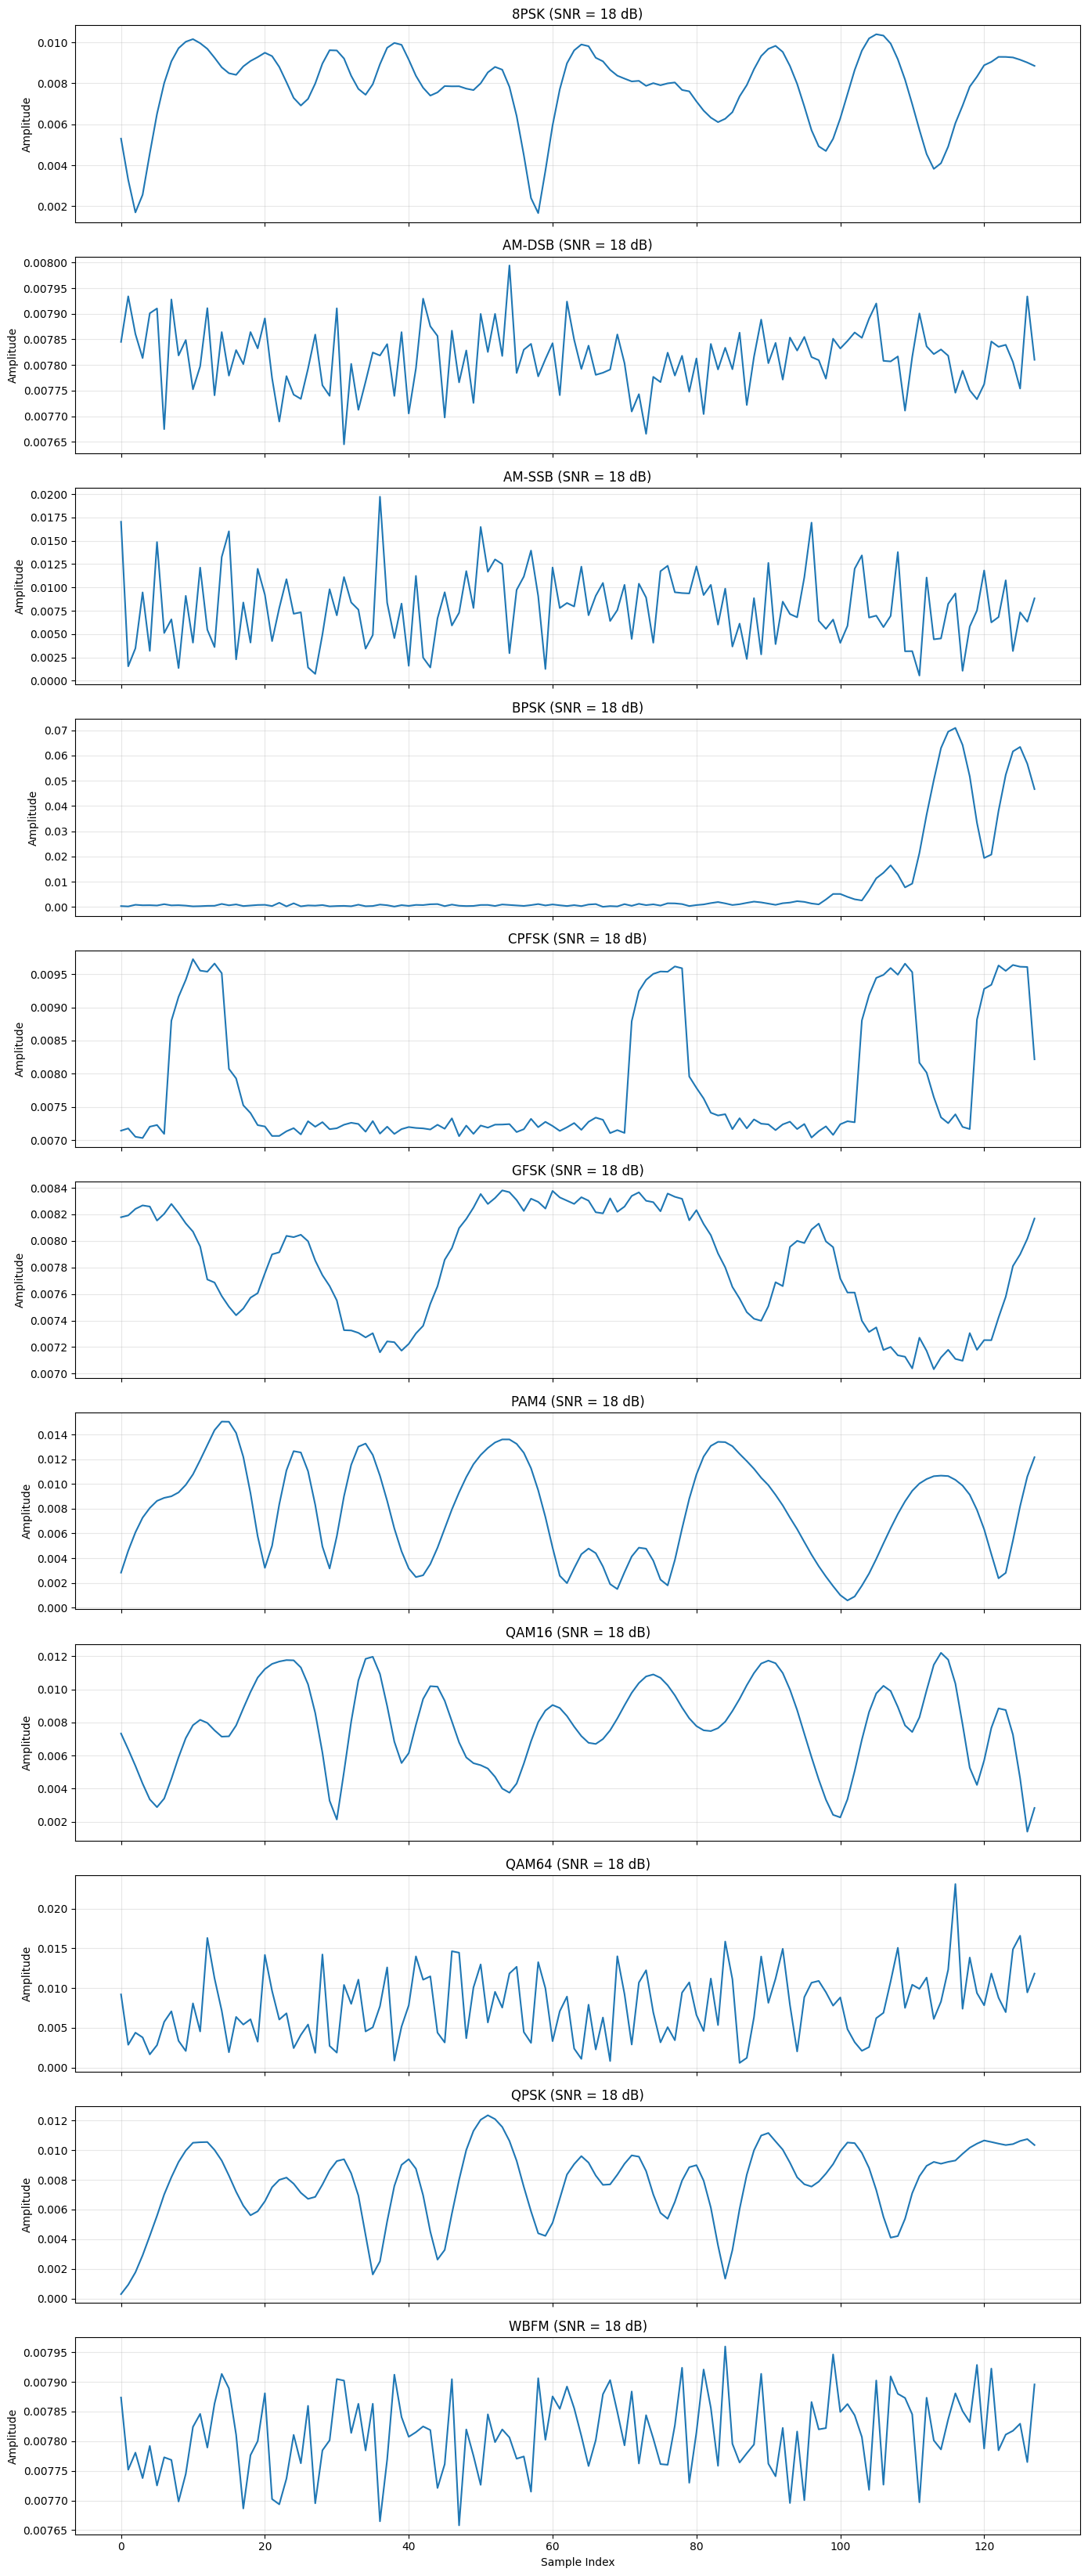

In [39]:
fig, axes = plt.subplots(
    len(modulations), 1,
    figsize=(14, 3 * len(modulations)),
    sharex=True
)

for ax, modulation in zip(axes, modulations):

    example = data[(modulation, selected_snr)][0]

    I = example[0]
    Q = example[1]

    amplitude = np.sqrt(I**2 + Q**2)
    samples = np.arange(len(amplitude))

    ax.plot(samples, amplitude)

    ax.set_title(f"{modulation} (SNR = {selected_snr} dB)")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sample Index")

plt.tight_layout()
plt.show()

- The instantaneous amplitude plots reveal different magnitude variations across the modulation classes at 18 dB SNR. BPSK exhibits large amplitude peaks toward the end of the signal, while CPFSK and GFSK show relatively smoother envelope variations. PAM4, QPSK, QAM16, and QAM64 display varying amplitude patterns, whereas AM-DSB and WBFM remain concentrated within narrow amplitude ranges.
- These differences illustrate how signal magnitude behaves across modulation schemes.

#### **Instantaneous phase**

- The instantaneous phase describes the angular position of each complex signal sample in the I/Q plane.
- It is calculated using $(\phi[n]=\operatorname{atan2}(Q[n],I[n]))$, producing phase values in the interval $([-\pi,\pi])$, where phase is an important characteristic of modulation schemes because information can be encoded through changes in the signal's phase.
- By plotting instantaneous phase over time for all modulation classes, we can examine their phase behavior and identify differences between modulation techniques.
- It is important to note that the phase representation is wrapped at the boundaries of $(-\pi)$ and $(\pi)$, so sudden jumps between these values may represent phase wrapping rather than actual abrupt changes in the signal, phase values can also become unreliable when the signal amplitude is close to zero.

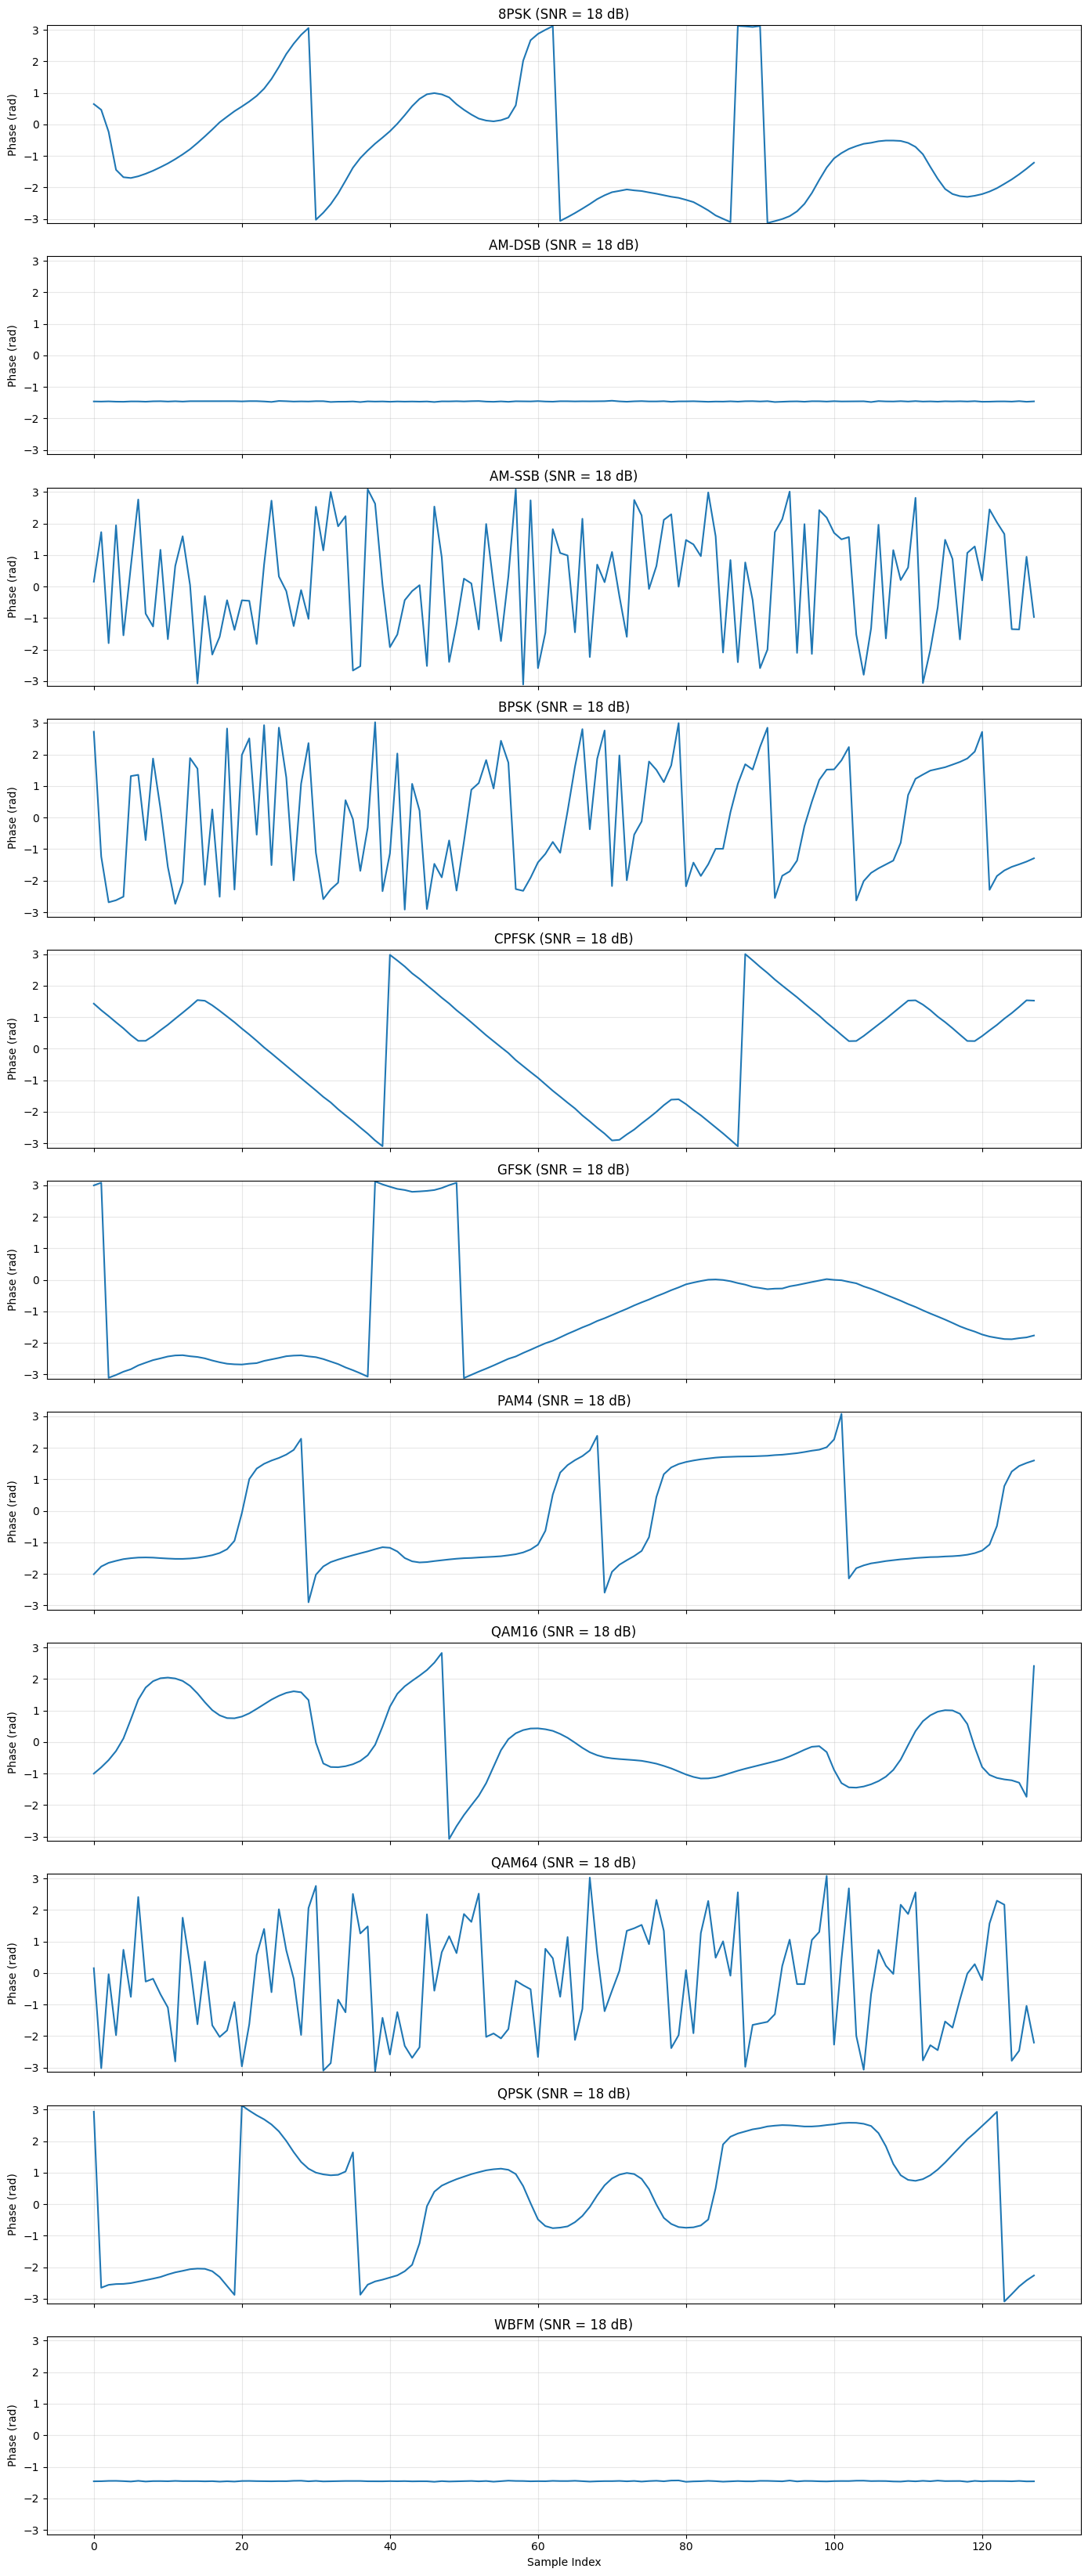

In [40]:
fig, axes = plt.subplots(
    len(modulations), 1,
    figsize=(14, 3 * len(modulations)),
    sharex=True
)

for ax, modulation in zip(axes, modulations):

    example = data[(modulation, selected_snr)][0]

    I = example[0]
    Q = example[1]

    phase = np.arctan2(Q, I)
    samples = np.arange(len(phase))

    ax.plot(samples, phase)

    ax.set_title(f"{modulation} (SNR = {selected_snr} dB)")
    ax.set_ylabel("Phase (rad)")
    ax.set_ylim(-np.pi, np.pi)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sample Index")

plt.tight_layout()
plt.show()

- the instantaneous phase plots show noticeable differences in phase evolution. 8PSK, QPSK and QAM schemes exhibit varying phase trajectories with visible wrapping between \(-\pi\) and \(+\pi\). CPFSK and GFSK show smoother, continuous phase evolution, while PAM4 displays several phase transitions. AM-DSB and WBFM maintain nearly constant phase throughout the selected examples.
- These patterns illustrate the different phase characteristics of the modulation schemes.

#### **Comparative analysis**

- The visualizations reveal complementary characteristics of the 11 modulation schemes :
  - Time domain plots illustrate differences in waveform evolution
  - I/Q scatter plots reveal their spatial distributions
  - amplitude plots show magnitude variations
  - phase plots highlight phase behavior
  
- Together, these representations demonstrate that modulation schemes encode information through different combinations of amplitude, phase, and frequency variations , combining them provides a more comprehensive understanding of the signal characteristics that an automatic modulation classification model can learn.

## 5. SNR and noise analysis

- Signal to Noise Ratio (SNR) describes the strength of a signal relative to background noise and is expressed in decibels (dB).
- It plays an important role in Automatic Modulation Classification because noise can alter the observed characteristics of a transmitted signal, making modulation schemes more difficult to distinguish.
- This section investigates the effect of different SNR conditions (-10 dB, 0 dB, and 18 dB) on signal waveforms, I/Q distributions, instantaneous amplitude, and phase.

#### **I/Q visualization at different SNR levels**

- Signal to Noise Ratio (SNR) measures the signal power relative to noise power, expressed in decibels.
  - A lower SNR indicates stronger noise relative to the signal, while a higher SNR indicates clearer signal conditions.
- Comparing I/Q waveforms at different SNR levels allows us to observe how noise affects signal variations and how the underlying waveform becomes more or less distinguishable.

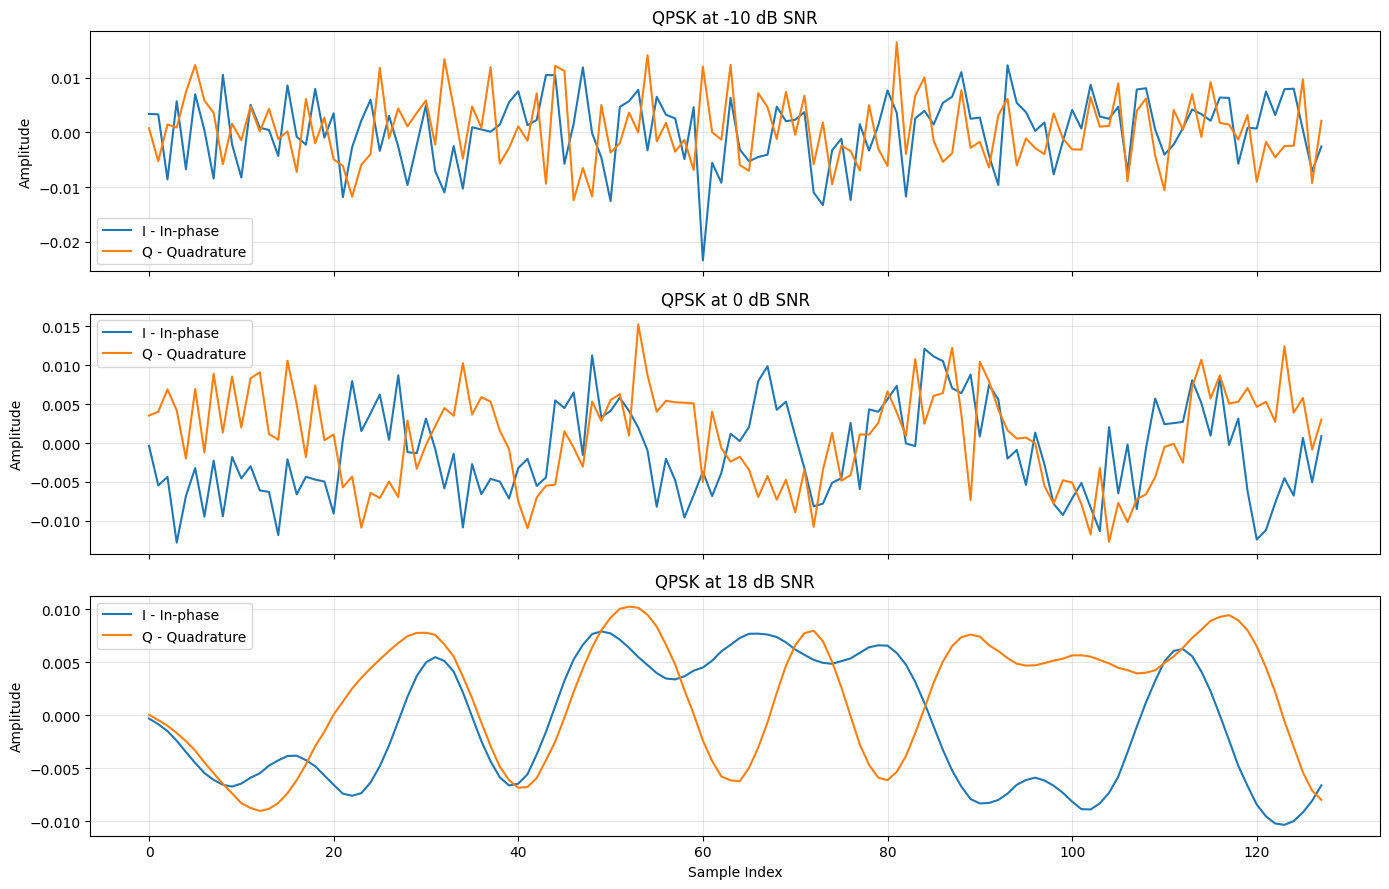

In [41]:
modulation = "QPSK"
snr_levels_to_compare = [-10, 0, 18]

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

for ax, snr in zip(axes, snr_levels_to_compare):

    example = data[(modulation, snr)][0]

    ax.plot(example[0], label="I - In-phase")
    ax.plot(example[1], label="Q - Quadrature")

    ax.set_title(f"{modulation} at {snr} dB SNR")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Sample Index")

plt.tight_layout()
plt.show()

- The QPSK waveforms show a clear relationship between SNR and signal quality.
  - At -10 dB, the I and Q components exhibit strong irregular fluctuations due to dominant noise.
  - At 0 dB, the underlying signal patterns become more noticeable, although considerable variations remain.
  - At 18 dB, the waveforms appear smoother and more structured, indicating reduced noise influence
  
- These observations demonstrate how increasing SNR improves signal quality and makes the underlying modulation characteristics easier to distinguish.

#### **Constellation diagrams across SNR levels**

- Constellation diagrams provide a spatial view of how noise affects the distribution of complex signal samples.
- By comparing QPSK samples at different SNR levels, we can observe how noise influences the concentration and dispersion of points in the I/Q plane.
- Lower SNR levels are expected to produce more dispersed distributions, while higher SNR levels generally reveal more structured signal patterns.

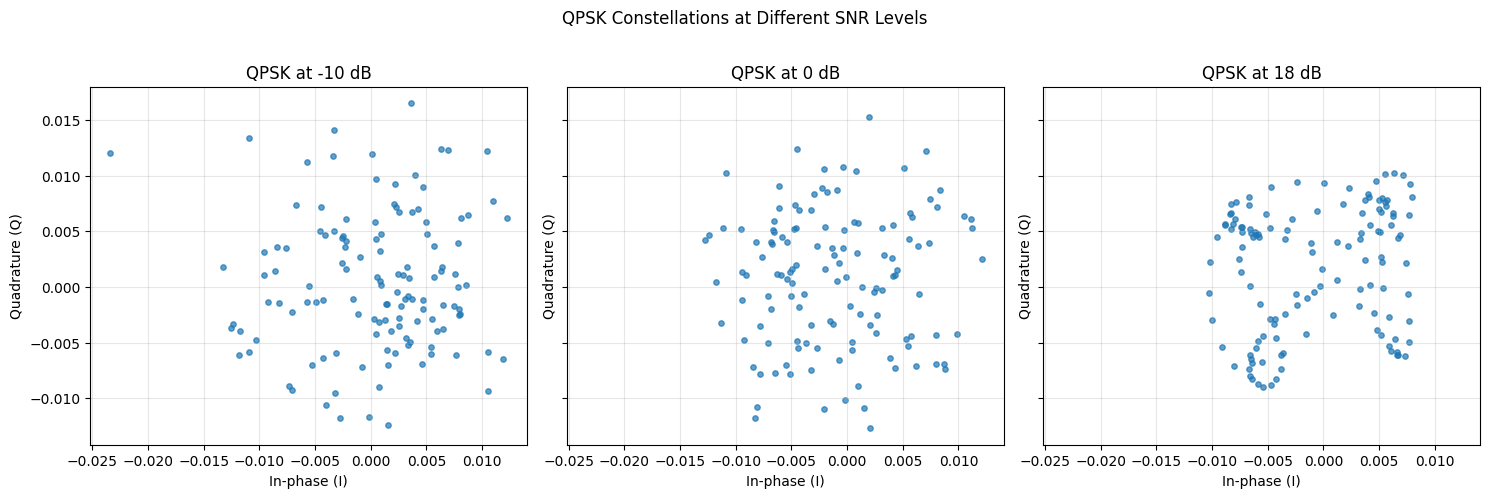

In [42]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for ax, snr in zip(axes, [-10, 0, 18]):

    example = data[("QPSK", snr)][0]

    I = example[0]
    Q = example[1]

    ax.scatter(I, Q, s=15, alpha=0.7)

    ax.set_title(f"QPSK at {snr} dB")
    ax.set_xlabel("In-phase (I)")
    ax.set_ylabel("Quadrature (Q)")
    ax.grid(alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle("QPSK Constellations at Different SNR Levels")
plt.tight_layout()
plt.show()

- The QPSK scatter plots demonstrate how SNR affects the spatial distribution of signal samples.
  - At -10 dB and 0 dB, the points form relatively dispersed distributions due to noise interference, making the underlying structure less apparent.
  - At 18 dB, more organized and distinguishable patterns emerge, revealing the signal's underlying characteristics more clearly.
  
- This illustrates how increasing SNR improves the visibility of signal structure in the I/Q plane.

#### **Amplitude and phase across SNR levels**

- Noise affects both the magnitude and phase of a received complex signal , so comparing instantaneous amplitude and phase across different SNR levels helps illustrate how signal disturbances influence these two properties.
- At lower SNR levels, noise is expected to cause stronger fluctuations and less stable phase estimates, whereas higher SNR levels generally produce more consistent signal characteristics.

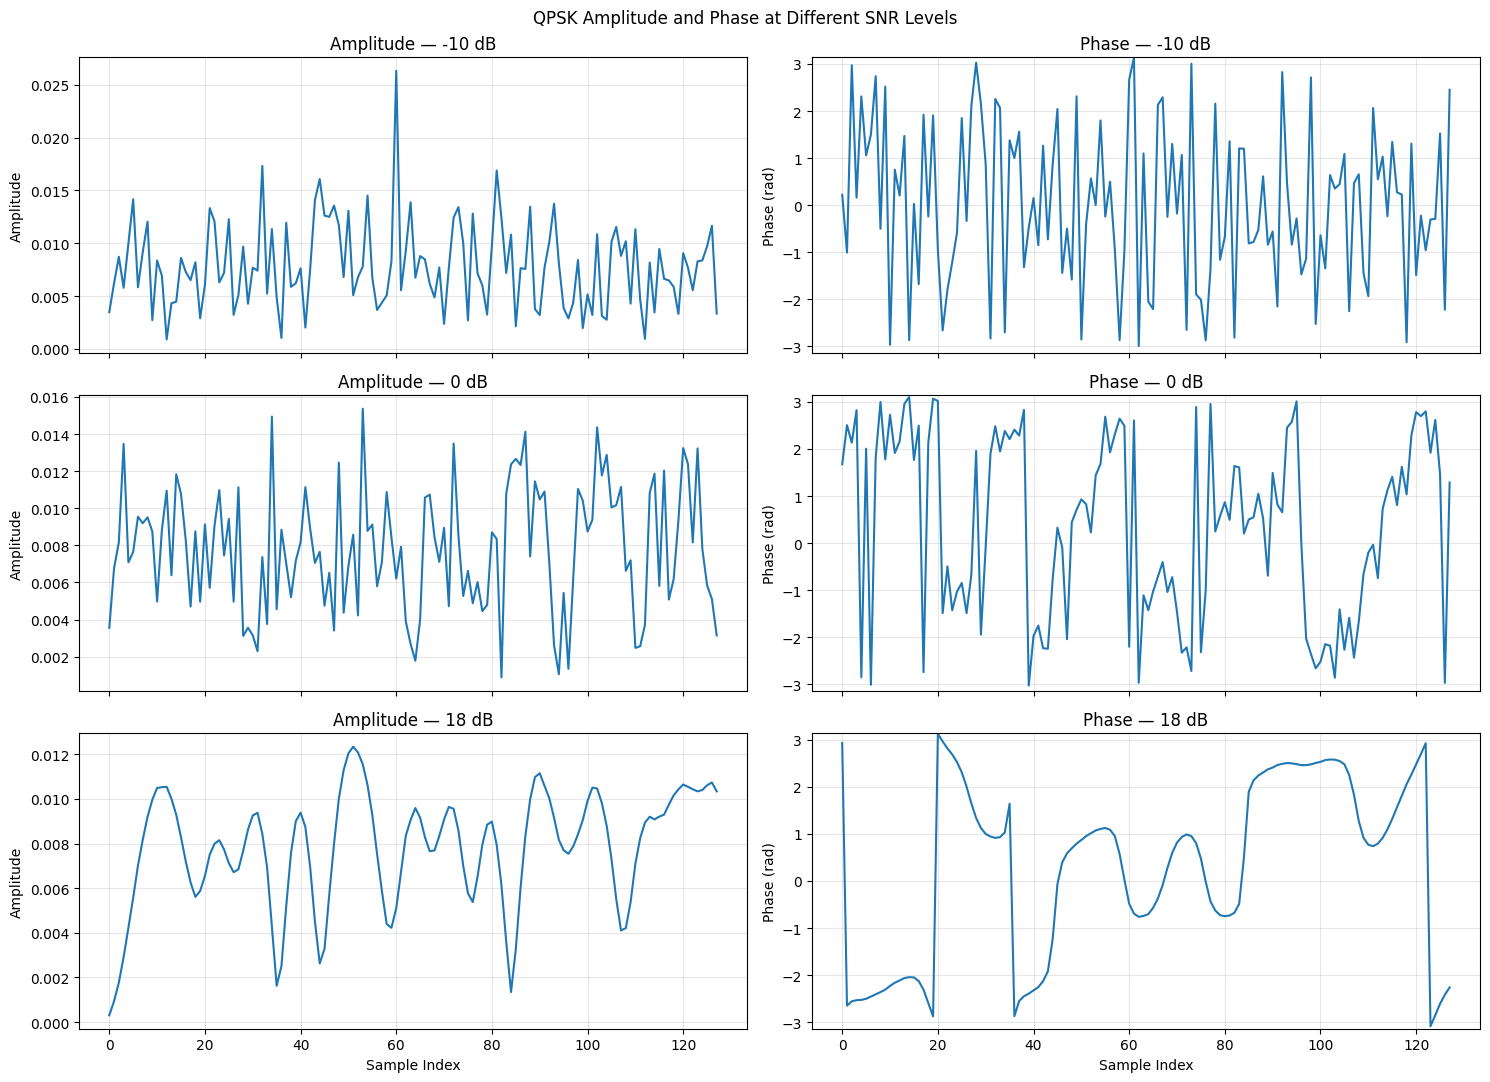

In [43]:
snr_levels_to_compare = [-10, 0, 18]

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 11),
    sharex=True
)

for row, snr in enumerate(snr_levels_to_compare):

    example = data[("QPSK", snr)][0]

    I = example[0]
    Q = example[1]

    amplitude = np.sqrt(I**2 + Q**2)
    phase = np.arctan2(Q, I)

    samples = np.arange(len(I))

    axes[row, 0].plot(samples, amplitude)
    axes[row, 0].set_title(f"Amplitude — {snr} dB")
    axes[row, 0].set_ylabel("Amplitude")
    axes[row, 0].grid(alpha=0.3)

    axes[row, 1].plot(samples, phase)
    axes[row, 1].set_title(f"Phase — {snr} dB")
    axes[row, 1].set_ylabel("Phase (rad)")
    axes[row, 1].set_ylim(-np.pi, np.pi)
    axes[row, 1].grid(alpha=0.3)

axes[-1, 0].set_xlabel("Sample Index")
axes[-1, 1].set_xlabel("Sample Index")

plt.suptitle("QPSK Amplitude and Phase at Different SNR Levels")
plt.tight_layout()
plt.show()

- The amplitude and phase comparisons reveal the influence of noise on two important signal properties.
  - At -10 dB and 0 dB, amplitude exhibits irregular fluctuations, while phase changes appear highly unstable.
  - At 18 dB, amplitude variations become smoother and phase evolution more structured.
  
- These observations demonstrate that noise affects both signal magnitude and phase, potentially making modulation characteristics harder to identify under low SNR conditions.

#### **SNR comparison summary**

- The analysis demonstrates that SNR strongly influences the observable characteristics of modulated signals.
   - At low SNR, noise disturbs waveform patterns and increases dispersion in the I/Q plane, making amplitude and phase behavior less structured.
   - At higher SNR, the underlying signal characteristics become more visible and easier to distinguish.
   
- This highlights the importance of noise robustness in Automatic Modulation Classification, as a reliable model must recognize modulation schemes under both clean and noisy conditions.

## 6. statistical signal analysis

- Visualizations provide an intuitive understanding of signal characteristics, but numerical statistics allow us to quantify them.
- This section examines the statistical properties of the I/Q signals, including their mean, standard deviation, amplitude, power, and energy, since these measurements provide additional information about signal behavior and help compare modulation classes under different SNR conditions.

#### **signal statistics**

- We begin by calculating basic statistical properties for each modulation class at 18 dB SNR, the mean describes the average component value, while the standard deviation measures its variability.
- We also examine the instantaneous amplitude to understand the magnitude distribution of each signal class.
- All 1,000 examples per class are included to obtain more representative statistics.

In [44]:
statistics = []

for modulation in modulations:

    signals = data[(modulation, 18)]

    I = signals[:, 0, :]
    Q = signals[:, 1, :]

    amplitude = np.sqrt(I**2 + Q**2)

    statistics.append({
        "Modulation": modulation,
        "Mean I": np.mean(I),
        "Mean Q": np.mean(Q),
        "Std I": np.std(I),
        "Std Q": np.std(Q),
        "Mean Amplitude": np.mean(amplitude),
        "Std Amplitude": np.std(amplitude),
        "Min Amplitude": np.min(amplitude),
        "Max Amplitude": np.max(amplitude)
    })

statistics_df = pd.DataFrame(statistics).set_index("Modulation")

display(statistics_df.round(6))

,Mean I,Mean Q,Std I,Std Q,Mean Amplitude,Std Amplitude,Min Amplitude,Max Amplitude
Modulation,,,,,,,,
8PSK,-0.000082,-0.000027,0.005775,0.005776,0.007812,0.002383,0.000012,0.097794
AM-DSB,0.001959,-0.005592,0.003909,0.003265,0.007812,0.000099,0.007248,0.008477
AM-SSB,-0.000180,-0.000032,0.006227,0.006277,0.007812,0.004144,0.000063,0.029183
BPSK,0.000023,-0.000003,0.005349,0.006541,0.007812,0.003219,0.000011,0.164239
CPFSK,-0.000003,0.000007,0.005543,0.005546,0.007812,0.000675,0.005725,0.010573
GFSK,-0.000054,-0.000115,0.005524,0.005532,0.007812,0.000299,0.006605,0.009311
PAM4,-0.000024,0.000034,0.004257,0.008010,0.007812,0.004610,0.000004,0.114294
QAM16,0.000020,-0.000015,0.005967,0.006016,0.007812,0.003281,0.000012,0.087861
QAM64,0.000112,-0.000034,0.005995,0.006041,0.007812,0.003378,0.000013,0.081993


- The statistical results show that the I and Q components generally have means close to zero across modulation classes, while their standard deviations vary.
- Amplitude variability differs considerably between schemes: CPFSK, GFSK, AM-DSB, and WBFM exhibit relatively low amplitude variation, whereas PAM4, AM-SSB, and higher-order modulation schemes show greater variability.
- These differences highlight how statistical measurements can help characterize modulation signals. Interestingly, the mean amplitude is nearly identical across all classes, suggesting a possible normalization property in the dataset.

#### **signal power and energy**

- Signal power measures the average strength of a signal, while energy represents the total accumulated squared magnitude over its samples.
- For complex I/Q signals, instantaneous power is calculated from the squared magnitudes of both components.
- We calculate average power and total energy for every example, then summarize their mean values for each modulation class.

- The relationship between the two quantities is:
  $$
  E = P_{\text{avg}} \times N
  $$

  where $(N=128)$ samples per signal.

In [45]:
power_results = []

for modulation in modulations:

    signals = data[(modulation, 18)]

    I = signals[:, 0, :]
    Q = signals[:, 1, :]

    instantaneous_power = I**2 + Q**2

    sample_power = np.mean(instantaneous_power, axis=1)
    sample_energy = np.sum(instantaneous_power, axis=1)

    power_results.append({
        "Modulation": modulation,
        "Mean Power": np.mean(sample_power),
        "Power Std": np.std(sample_power),
        "Mean Energy": np.mean(sample_energy)
    })

power_df = pd.DataFrame(power_results).set_index("Modulation")

display(power_df.round(8))

,Mean Power,Power Std,Mean Energy
Modulation,,,
8PSK,0.000067,1.549000e-05,0.008540
AM-DSB,0.000061,2.000000e-08,0.007814
AM-SSB,0.000078,2.220000e-06,0.010010
BPSK,0.000071,2.105000e-05,0.009139
CPFSK,0.000061,3.700000e-07,0.007871
GFSK,0.000061,9.000000e-08,0.007824
PAM4,0.000082,1.758000e-05,0.010532
QAM16,0.000072,1.241000e-05,0.009190
QAM64,0.000072,1.158000e-05,0.009273


- The power and energy measurements reveal variations in signal strength across modulation classes.
  - PAM4 and AM-SSB exhibit relatively higher average power and energy, while AM-DSB, CPFSK, GFSK, and WBFM show lower values.
  - The power standard deviation also indicates that some classes have more consistent power levels than others.
  
- Since signal energy is calculated from average power over 128 samples, both measurements provide complementary ways of describing signal strength.

#### **statistics across SNR levels**

- Finally, we investigate how statistical properties change with SNR by examining QPSK signals at -10, 0, and 18 dB.
- We calculate average signal power, mean amplitude, and amplitude variability using all available examples at each SNR level.
- This numerical comparison complements the previous visual analysis and helps quantify differences between noisy and relatively clean signal conditions.

In [46]:
snr_statistics = []

for snr in [-10, 0, 18]:

    signals = data[("QPSK", snr)]

    I = signals[:, 0, :]
    Q = signals[:, 1, :]

    amplitude = np.sqrt(I**2 + Q**2)
    power = I**2 + Q**2

    snr_statistics.append({
        "SNR (dB)": snr,
        "Mean Power": np.mean(power),
        "Power Std": np.std(np.mean(power, axis=1)),
        "Mean Amplitude": np.mean(amplitude),
        "Amplitude Std": np.std(amplitude)
    })

snr_statistics_df = pd.DataFrame(snr_statistics).set_index("SNR (dB)")

display(snr_statistics_df.round(8))

,Mean Power,Power Std,Mean Amplitude,Amplitude Std
SNR (dB),,,,
-10,0.000078,0.000002,0.007812,0.004125
0,0.000071,0.000002,0.007812,0.003143
18,0.000067,0.000017,0.007812,0.002462


- The QPSK statistics show a decrease in average measured power and amplitude variability as SNR increases from -10 dB to 18 dB.
  - The amplitude standard deviation decreases from 0.004125 to 0.002462, indicating less variation under higher-SNR conditions.
  
- These results are consistent with the visual observations in Section 5, where higher SNR produced more structured waveforms.

## 7. frequency domain analysis

- Frequency domain analysis examines how signal power is distributed across different frequency components. Using the Fast Fourier Transform (FFT), we convert I/Q signals from the time domain into the frequency domain.
- This helps us investigate spectral characteristics across modulation schemes and understand how different SNR conditions affect the frequency content of received signals.

#### **frequency Spectrum Across Modulation Classes**

- Different modulation schemes can exhibit different spectral characteristics depending on how information is encoded in the signal.
- In this analysis, we calculate the average power spectrum for all 11 modulation classes at 18 dB SNR, since averaging across multiple examples provides a more representative view than examining a single signal.

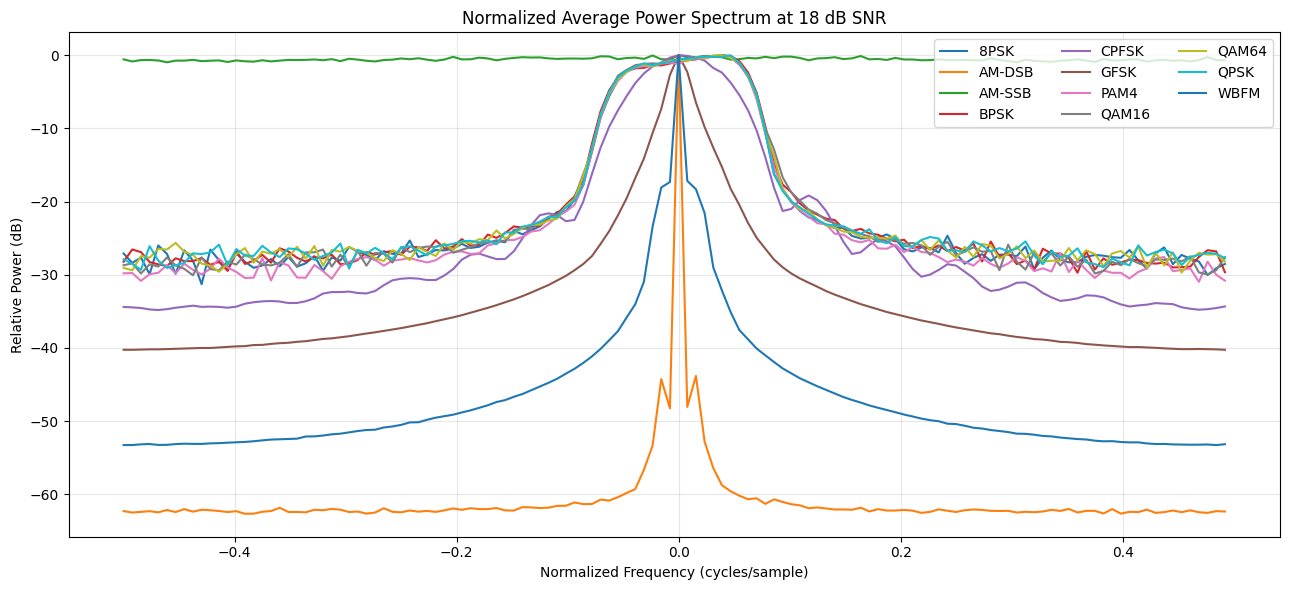

In [47]:
plt.figure(figsize=(13, 6))

for modulation in modulations:

    signals = data[(modulation, 18)]
    complex_signals = signals[:, 0, :] + 1j * signals[:, 1, :]

    fft_values = np.fft.fftshift(
        np.fft.fft(complex_signals, axis=1),
        axes=1
    )

    power_spectrum = np.mean(np.abs(fft_values)**2, axis=0)

    # Normalize each spectrum to its maximum
    power_db = 10 * np.log10(
        power_spectrum / np.max(power_spectrum) + 1e-12
    )

    frequencies = np.fft.fftshift(np.fft.fftfreq(128))

    plt.plot(frequencies, power_db, label=modulation)

plt.title("Normalized Average Power Spectrum at 18 dB SNR")
plt.xlabel("Normalized Frequency (cycles/sample)")
plt.ylabel("Relative Power (dB)")
plt.grid(alpha=0.3)
plt.legend(ncol=3)
plt.tight_layout()
plt.show()

- The average power spectra reveal differences in frequency distribution across modulation classes, some schemes exhibit relatively concentrated spectral peaks around the central frequency, while others show broader distributions , however, several modulation classes have overlapping spectral patterns, indicating that frequency domain characteristics alone may not be sufficient to distinguish every modulation scheme.
- Combining spectral information with time domain and I/Q characteristics provides a more comprehensive signal representation.

#### **frequency Spectrum Across SNR Levels**



- Noise affects the frequency domain representation of a signal by changing its spectral power distribution.
- We compare the average QPSK power spectrum at -10, 0, and 18 dB SNR to examine how the frequency content changes under different noise conditions.

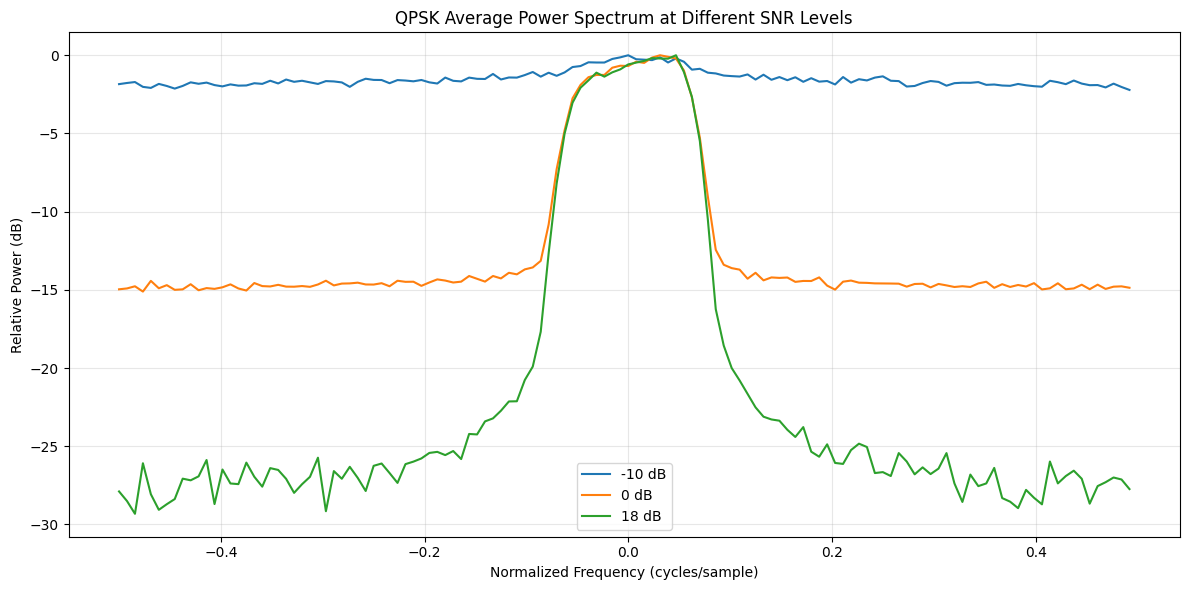

In [48]:
plt.figure(figsize=(12, 6))

for snr in [-10, 0, 18]:

    signals = data[("QPSK", snr)]
    complex_signals = signals[:, 0, :] + 1j * signals[:, 1, :]

    fft_values = np.fft.fftshift(
        np.fft.fft(complex_signals, axis=1),
        axes=1
    )

    power_spectrum = np.mean(np.abs(fft_values)**2, axis=0)

    power_db = 10 * np.log10(
        power_spectrum / np.max(power_spectrum) + 1e-12
    )

    frequencies = np.fft.fftshift(np.fft.fftfreq(128))

    plt.plot(frequencies, power_db, label=f"{snr} dB")

plt.title("QPSK Average Power Spectrum at Different SNR Levels")
plt.xlabel("Normalized Frequency (cycles/sample)")
plt.ylabel("Relative Power (dB)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

- The QPSK spectra demonstrate how SNR affects the frequency domain representation.
  - At -10 dB, the spectrum is relatively flat, reflecting the strong influence of noise.
  - At 0 dB, a more noticeable central spectral structure emerges
  - At 18 dB, the signal exhibits a clearer concentrated frequency distribution and a lower relative noise floor.
  
- These observations show how higher SNR makes the underlying spectral characteristics more distinguishable.

#### **Overall findings**


- Frequency domain analysis reveals that modulation schemes exhibit different spectral distributions, although some patterns overlap.
- Comparing QPSK across SNR levels also demonstrates how noise influences spectral characteristics, potentially making modulation identification more difficult under noisy conditions.
- Therefore, frequency domain features provide useful complementary information for Automatic Modulation Classification when combined with time domain and I/Q representations.

## 8. EDA and key findings

#### **Dataset Overview and Structure**

- The RadioML 2016.10a dataset contains 220,000 complex valued signal examples distributed across 11 modulation classes and 20 SNR levels, ranging from -20 dB to 18 dB.
- Each example consists of 128 samples represented by two components: In phase (I) and Quadrature (Q).
- The dataset contains 1,000 examples for every (modulation,SNR) combination, resulting in a balanced distribution across both dimensions.

#### **Main EDA findings**

- The exploratory analysis revealed several important characteristics of the dataset.
  - First, modulation schemes exhibit distinct waveform, amplitude, phase, and I/Q distribution patterns.
  - Second, SNR strongly influences signal quality: lower SNR conditions introduce greater noise interference and make signal characteristics less distinguishable.
  - Third, statistical measurements reveal differences in amplitude variability and signal power across modulation classes.
  - Finally, frequency domain analysis provides complementary spectral information, although some modulation schemes exhibit overlapping frequency patterns.
- Together, these findings highlight the importance of learning multiple signal characteristics for reliable modulation classification.

#### **data quality**

- The dataset passed the structural and numerical integrity checks, with all expected (modulation,SNR) combinations present, consistent signal dimensions, and no detected NaN or infinite values.

#### **Implications for Automatic Modulation Classification**

- The EDA demonstrates that Automatic Modulation Classification is a challenging task because modulation schemes differ across several signal characteristics, while noise can obscure these differences.
- Deep Learning models can learn complex patterns directly from raw I/Q samples, potentially capturing relationships that are difficult to describe using individual statistical or spectral features.
- The observed sensitivity to SNR also motivates evaluating model performance across different noise conditions to assess its robustness and generalization ability.